# OULAD Milestone 2: Exploratory Data Analysis

**Research topic:** Machine Learning Based Prediction of Student Academic Performance in Open University Settings Using Online Engagement  
**Student:** Nyasha Grace Manyonganise  
**Student number:** ST10538027  
**Module:** RPD8412w

## Purpose of this notebook

This notebook performs the formal exploratory data analysis on the validated analytical datasets created during data preparation. It compares the week-two, week-four and week-six prediction windows before model training.

The analysis covers target balance, missing values, numerical distributions, categorical outcome rates, bivariate relationships, window comparisons, correlations, multivariate relationships and outlier review. EDA helps us understand the data, but it does not prove causation or replace final held out model evaluation.


## 1. Concepts used in this notebook

**Exploratory data analysis** examines the structure, distributions and relationships in a dataset before formal modelling. It helps identify unusual values, missing data, class imbalance and possible relationships that should be considered during modelling (James et al., 2021).

**Univariate analysis** examines one variable at a time. **Bivariate analysis** examines a relationship between two variables. **Multivariate analysis** examines several variables together.

**Data leakage** occurs when information unavailable at prediction time is used as a predictor. The final outcome and later withdrawal information must not be used as early predictors (James et al., 2021).


## 2. Loading the analytical datasets

The saved analytical datasets are loaded instead of rebuilding the raw OULAD tables. This keeps data preparation and EDA as separate, reproducible stages.


In [18]:
# Loading libraries for EDA
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [19]:
# Finding the output folder and loading the three prediction windows
candidate_folders = [Path.cwd() / "oulad_outputs", Path.cwd().parent / "oulad_outputs", Path("/content/oulad_outputs")]
output_folder = next((folder for folder in candidate_folders if folder.exists()), None)
if output_folder is None:
    raise FileNotFoundError("The oulad_outputs folder was not found. Place this notebook beside the preparation output folder.")

eda_folder = output_folder / "eda"
eda_folder.mkdir(exist_ok=True)
window_files = {window: output_folder / f"oulad_analytical_week_{window}.csv" for window in [2, 4, 6]}
missing_files = [str(path) for path in window_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing analytical files: {missing_files}")

analytical_datasets = {}
for window, path in window_files.items():
    print(f"Loading Week {window} analytical dataset...")
    data = pd.read_csv(path, low_memory=False)
    data.columns = data.columns.astype(str).str.strip()
    analytical_datasets[window] = data
    print(f"Week {window}: {data.shape[0]:,} rows and {data.shape[1]} columns")
print("All three analytical datasets loaded successfully.")


Loading Week 2 analytical dataset...
Week 2: 32,593 rows and 40 columns
Loading Week 4 analytical dataset...
Week 4: 32,593 rows and 42 columns
Loading Week 6 analytical dataset...
Week 6: 32,593 rows and 42 columns
All three analytical datasets loaded successfully.


### Meaning of the loading result

The three analytical datasets loaded successfully. Each dataset contains 32,593 rows, indicating that the same number of student module presentation records was retained for the Week 2, Week 4 and Week 6 prediction windows.

Week 2 contains 40 columns, while Weeks 4 and 6 contain 42 columns. This difference indicates that additional engagement or assessment features are available in the later prediction windows. The next checks will confirm whether the student level keys are unique and whether the target distribution remains consistent across the three datasets.



## 3. Population, target and leakage checks

### This section checks the student-level key, the target values and the columns that must not be used as predictors. The final outcome is the label to be predicted, not an input variable.


These checks are performed to confirm that the analytical datasets have the correct structure before further exploratory analysis. Data exploration should begin by identifying what each row represents, what each column measures and whether the variables contain missing, repeated or unsuitable values (Ozdemir, 2016).

The student-level key consists of **id_student**, **code_module** and **code_presentation**. Together, these columns identify a student's record for a particular module and presentation. Checking for repeated keys helps confirm that students have not been unintentionally duplicated in the analytical datasets.

The target column represents the outcome that the supervised machine-learning models will predict. The predictor columns are the input variables used to make that prediction. The target must therefore be checked separately and must not be included as a predictor (Ozdemir, 2016).

The three prediction windows must contain the same student population so that any difference in model performance can be interpreted as a difference in the available early information rather than a difference in the students included. Columns containing identifiers, the final outcome, the prediction-window label and later withdrawal information are excluded from predictor analysis to reduce the risk of data leakage.

The checks below examine duplicate student-level keys, target encoding, population consistency and columns that must be excluded from later modelling.


In [20]:
# Defining the columns that identify one student in one module presentation
student_key = [
    "id_student",
    "code_module",
    "code_presentation"
]

# Listing columns that must not be used as model predictors
# These columns are identifiers, outcome columns, or possible leakage variables
excluded_columns = student_key + [
    "final_result",
    "target",
    "prediction_window_week",
    "date_unregistration"
]

# Checking each prediction-window dataset separately
for window, data in analytical_datasets.items():

    # Counting repeated student-level keys
    # A result of zero means that no student-module-presentation key is repeated
    duplicate_key_count = data.duplicated(student_key).sum()

    # Checking which target values are present
    # The dropna method ignores missing target values during this check
    observed_target_values = sorted(
        data["target"].dropna().unique().tolist()
    )

    # Counting missing target values
    # A missing target would prevent that record from being used correctly
    missing_target_count = data["target"].isna().sum()

    # Printing the key-duplication result for the current window
    print(
        f"Week {window} duplicate student-level keys:",
        int(duplicate_key_count)
    )

    # Printing the target values found in the current window
    print(
        f"Week {window} target values:",
        observed_target_values
    )

    # Printing the number of missing target values
    print(
        f"Week {window} missing target values:",
        int(missing_target_count)
    )

# Creating a set of unique student-level keys for each prediction window
# A set stores each key only once, which makes population comparison easier
key_sets = {}

for window, data in analytical_datasets.items():

    # Removing repeated keys before creating the set
    # The result represents the unique student population in that window
    unique_keys = data[student_key].drop_duplicates()

    # Converting each key row into a tuple and storing all tuples in a set
    key_sets[window] = set(map(tuple, unique_keys.to_numpy()))

# Finding the keys that occur in every prediction window
# This shows the number of student records shared by Weeks 2, 4 and 6
common_keys = set.intersection(*key_sets.values())

# Finding the keys that occur in at least one prediction window
# This shows the total population represented across all three datasets
all_keys = set.union(*key_sets.values())

# Printing the number of records shared by all windows
print(
    "Keys common to all windows:",
    len(common_keys)
)

# Printing the total number of different records across all windows
print(
    "Keys present in at least one window:",
    len(all_keys)
)

# Displaying the columns that have been identified for exclusion
# This documents the columns that must be left out of the modelling predictors
print(
    "Excluded columns checked:",
    excluded_columns
)


Week 2 duplicate student-level keys: 0
Week 2 target values: [0, 1]
Week 2 missing target values: 0
Week 4 duplicate student-level keys: 0
Week 4 target values: [0, 1]
Week 4 missing target values: 0
Week 6 duplicate student-level keys: 0
Week 6 target values: [0, 1]
Week 6 missing target values: 0
Keys common to all windows: 32593
Keys present in at least one window: 32593
Excluded columns checked: ['id_student', 'code_module', 'code_presentation', 'final_result', 'target', 'prediction_window_week', 'date_unregistration']


### Meaning of the population, target and leakage results

The duplicate key check returned zero for Weeks 2, 4 and 6. This indicates that no student module presentation key was repeated in any of the three analytical datasets. Therefore, no student record appears to have been duplicated at the modelling level.

The target values were **[0, 1]** in all three windows. This confirms that the observed target values were successfully represented using two binary classes. The additional missing target check confirms whether any records require investigation before modelling.

The number of keys common to all three windows was 32,593, and the number of keys present in at least one window was also 32,593. Together with the absence of duplicate keys and the earlier row-count results, this confirms that the three prediction windows contain the same student-level population.

The excluded-column list documents the variables that must not be used as predictors. Identifiers do not represent meaningful student behaviour, while **final_result** and **target** contain outcome information. **prediction_window_week** identifies the dataset version, and **date_unregistration** may contain information from a later stage of the student journey. Excluding these variables reduces the risk of data leakage and supports a fair comparison between the Week 2, Week 4 and Week 6 models.

These checks confirm that the datasets are structurally comparable. They do not yet show which predictors are associated with the outcome. This means that question will be examined in the following EDA sections.



## 4. Checking dataset size, missingness and outcome balance across prediction windows

The purpose of this section is to compare the Week 2, Week 4 and Week 6 analytical datasets before examining individual features. The comparison checks whether the datasets contain the same number of student records, whether their structures are similar, how many missing cells they contain and whether the outcome classes remain balanced across the three prediction windows.

These checks are important because the three windows must be comparable. If one window contained different students or a different outcome distribution, differences in later model performance could be caused by changes in the dataset rather than by the amount of information available at Week 2, Week 4 or Week 6.

Exploratory data analysis uses summaries and visualisations to understand data structure, identify possible problems and examine relationships before formal modelling (Ozdemir, 2016).



,window,rows,columns,missing_cells,successful_count,adverse_count,successful_percent,adverse_percent
0,Week 2,32593,40,62855,15385,17208,47.2,52.8
1,Week 4,32593,42,54738,15385,17208,47.2,52.8
2,Week 6,32593,42,47647,15385,17208,47.2,52.8


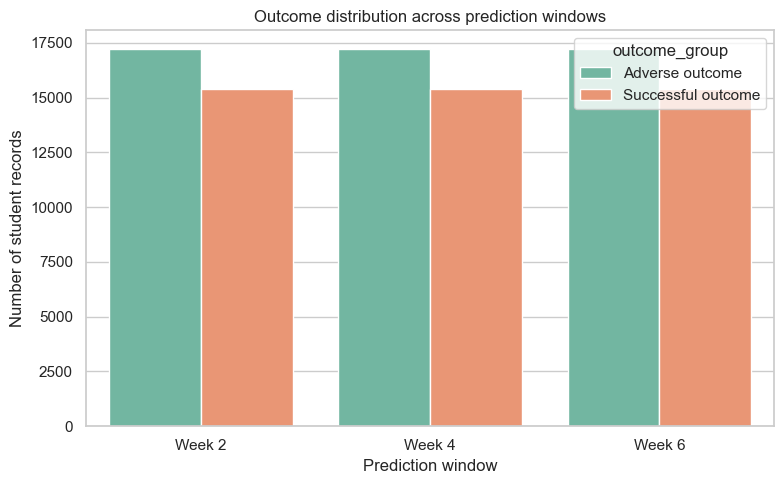

In [21]:
# Create an empty list for the dataset summary
overview = []

# Create an empty list for the outcome chart
plot_rows = []

# Process each prediction-window dataset
for window, data in analytical_datasets.items():

    # Calculate the percentage of successful outcomes
    successful_percentage = data["target"].mean() * 100

    # Calculate the percentage of adverse outcomes
    adverse_percentage = (1 - data["target"].mean()) * 100

    # Store the main results for this prediction window
    overview.append({
        "window": f"Week {window}",
        "rows": len(data),
        "columns": len(data.columns),
        "missing_cells": int(data.isna().sum().sum()),
        "successful_count": int((data["target"] == 1).sum()),
        "adverse_count": int((data["target"] == 0).sum()),
        "successful_percent": round(successful_percentage, 2),
        "adverse_percent": round(adverse_percentage, 2)
    })

    # Count each target class for the chart
    target_counts = data["target"].value_counts()

    # Add the adverse-outcome count to the chart data
    plot_rows.append({
        "window": f"Week {window}",
        "outcome_group": "Adverse outcome",
        "count": int(target_counts.get(0, 0))
    })

    # Add the successful-outcome count to the chart data
    plot_rows.append({
        "window": f"Week {window}",
        "outcome_group": "Successful outcome",
        "count": int(target_counts.get(1, 0))
    })

# Convert the summary list into a DataFrame
overview_df = pd.DataFrame(overview)

# Convert the chart list into a DataFrame
target_plot_df = pd.DataFrame(plot_rows)

# Display the numerical summary
display(overview_df)

# Save the numerical summary
overview_df.to_csv(
    eda_folder / "eda_dataset_overview.csv",
    index=False
)

# Create the outcome-distribution chart
plt.figure(figsize=(8, 5))

# Draw the successful and adverse outcome bars
sns.barplot(
    data=target_plot_df,
    x="window",
    y="count",
    hue="outcome_group",
    palette="Set2"
)

# Add a clear chart title
plt.title("Outcome distribution across prediction windows")

# Add the horizontal-axis label
plt.xlabel("Prediction window")

# Add the vertical-axis label
plt.ylabel("Number of student records")

# Arrange the chart neatly
plt.tight_layout()

# Save the chart
plt.savefig(
    eda_folder / "target_distribution_by_window.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()


### Meaning of the dataset size and outcome balance results

The Week 2, Week 4 and Week 6 datasets each contain 32,593 rows. This indicates that the same number of student-module-presentation records was retained across all three prediction windows.

Week 2 contains 40 columns, while Weeks 4 and 6 contain 42 columns. This indicates that additional predictor features are available in the later prediction windows.

The total number of missing cells is 62,855 for Week 2, 54,738 for Week 4 and 47,647 for Week 6. Although the total number of missing cells decreases across the windows, this should not automatically be interpreted as an improvement in data quality because the number of columns and the feature-construction decisions can affect the total. The missing value section will examine the affected variables in more detail.

The outcome counts are identical across all three windows. There are 15,385 successful outcomes and 17,208 adverse outcomes in each dataset. This corresponds to 47.2% successful outcomes and 52.8% adverse outcomes.

The chart confirms that the outcome distribution remains unchanged across Weeks 2, 4 and 6. This is important because the three prediction windows can now be compared using the same student population and the same outcome distribution.

The adverse outcome class is the majority class at 52.8%. A model that always predicted the adverse outcome would therefore achieve an accuracy of 52.8%. This is the majority-class baseline, which will later be used as a simple reference point when interpreting model performance. In classification, the null or majority class model predicts the most common outcome (Ozdemir, 2016).


## 5. Missing-value analysis

Missing values are reviewed before modelling decisions are made. A missing assessment score is not automatically equivalent to a zero score.


,window,column,missing_count,missing_percent
0,Week 2,avg_TMA_score,31405,96.36
1,Week 2,assessment_score_mean,31405,96.36
2,Week 2,date_registration,45,0.14
3,Week 4,avg_CMA_score,28320,86.89
4,Week 4,avg_TMA_score,14852,45.57
5,Week 4,assessment_score_mean,11521,35.35
6,Week 4,date_registration,45,0.14
7,Week 6,avg_CMA_score,28320,86.89
8,Week 6,avg_TMA_score,10188,31.26
9,Week 6,assessment_score_mean,9094,27.90


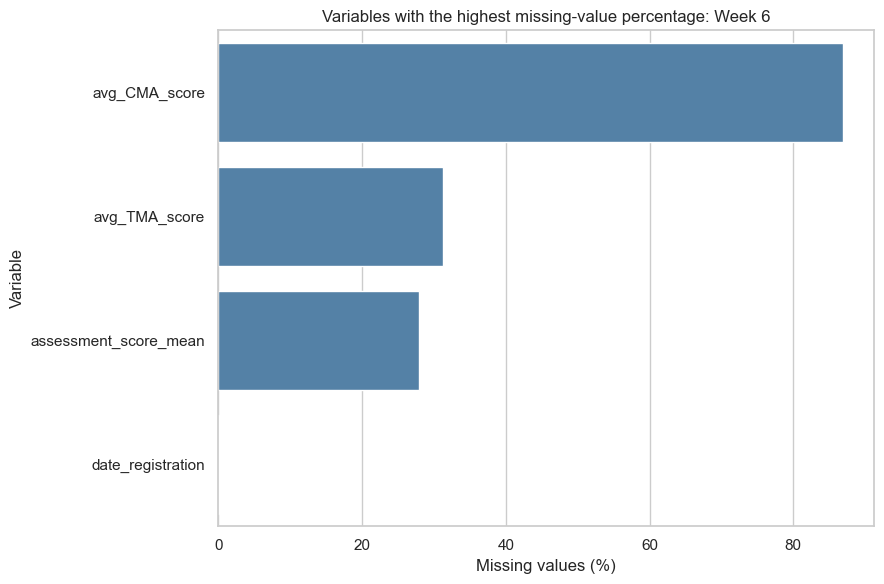

In [22]:
# Summarising missing values and plotting the main Week 6 missingness pattern
missing_rows = []
for window, data in analytical_datasets.items():
    counts = data.isna().sum().sort_values(ascending=False)
    for column, count in counts[counts > 0].items():
        missing_rows.append({"window": f"Week {window}", "column": column, "missing_count": int(count), "missing_percent": round(count / len(data) * 100, 2)})

missing_df = pd.DataFrame(missing_rows)
display(missing_df.head(30))
missing_df.to_csv(eda_folder / "missing_value_summary.csv", index=False)

week6 = analytical_datasets[6].copy()
missing_percent = (week6.isna().mean() * 100).sort_values(ascending=False)
missing_percent = missing_percent[missing_percent > 0].head(20)
if len(missing_percent) > 0:
    plt.figure(figsize=(9, 6))
    sns.barplot(x=missing_percent.values, y=missing_percent.index, color="steelblue")
    plt.title("Variables with the highest missing-value percentage: Week 6")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.savefig(eda_folder / "missing_values_week6.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No missing values were found in Week 6.")


### Meaning of the missing value results

The missing value summary shows that missingness is concentrated mainly in the assessment-score features rather than in the registration variable.

For Week 2, **avg_TMA_score** and **assessment_score_mean** are missing for 31,405 records, representing 96.36% of the dataset. This indicates that valid formative assessment scores were unavailable for most students by the Week 2 cutoff. This is plausible because Week 2 is the earliest prediction window and fewer assessments may have taken place by that point.

For Week 4, missingness decreases to 45.57% for **avg_TMA_score** and 35.35% for **assessment_score_mean**. This indicates that more assessment information became available by Week 4.

For Week 6, missingness decreases further to 31.26% for  **avg_TMA_score** and 27.90% for **assessment_score_mean**. This shows that assessment information accumulated as the prediction window became longer.

The **avg_CMA_score** variable has 28,320 missing values in Week 4 and Week 6, representing 86.89% of the records. This means that a valid CMA score was unavailable for most students within these early windows. However, it is not automatically be interpreted as evidence that students failed to complete the CMA, because missingness may also mean that the assessment was not yet available or that no valid score was recorded.

Only 45 **date_registration** values are missing in each window, representing 0.14% of the dataset. This is a very small and stable amount of missingness compared with the assessment variables.

The Week 6 graph confirms that the assessment score variables have the highest missing value percentages in that dataset. The registration variable has such a small percentage of missing values that its bar is almost invisible.

These results show why missing assessment scores should not automatically be replaced with zero. A zero would mean that a student received no marks, whereas a missing value means that a valid score was unavailable. The later modelling pipeline should therefore apply a documented imputation method and retain missingness indicators for the score variables.



## 6.Univariet Numerical feature distributions and comparison by outcome group

The purpose of this section is to examine the distribution of each numerical feature in the Week 6 analytical dataset. The descriptive statistics show the centre, spread and range of each variable, while the histograms show how the values are distributed.

The features are also displayed separately for successful and adverse outcome groups. This allows the distributions to be compared visually and helps identify whether some features may contain useful predictive information. These are descriptive comparisons only and do not prove that any feature causes the final outcome.

The count based variables are displayed using a log-transformed scale.  The transformation is used only for visualisation and does not change the original analytical dataset. The mean, median, standard deviation, quartiles and maximum value are considered together because the mean can be affected by extreme values, while the median is generally less affected by outliers (Ozdemir, 2016).

Numerical features selected for Week 2:
['total_clicks', 'active_days', 'unique_learning_sites', 'interaction_records', 'assessment_record_count', 'scored_assessment_count', 'submitted_assessment_count', 'assessment_submission_rate', 'assessment_score_mean', 'avg_TMA_score', 'num_of_prev_attempts', 'studied_credits']


,count,mean,std,min,25%,50%,75%,max,window
total_clicks,32593.0,21.034670,106.197416,0.0,0.0,0.0,0.0,3210.0,Week 2
active_days,32593.0,0.956985,3.354155,0.0,0.0,0.0,0.0,39.0,Week 2
unique_learning_sites,32593.0,1.915810,6.151921,0.0,0.0,0.0,0.0,104.0,Week 2
interaction_records,32593.0,5.768171,22.214342,0.0,0.0,0.0,0.0,391.0,Week 2
assessment_record_count,32593.0,0.036480,0.187485,0.0,0.0,0.0,0.0,1.0,Week 2
scored_assessment_count,32593.0,0.036450,0.187409,0.0,0.0,0.0,0.0,1.0,Week 2
submitted_assessment_count,32593.0,0.034915,0.183569,0.0,0.0,0.0,0.0,1.0,Week 2
assessment_submission_rate,32593.0,0.034915,0.183569,0.0,0.0,0.0,0.0,1.0,Week 2
assessment_score_mean,1188.0,71.149832,12.139228,15.0,63.0,72.0,80.0,98.0,Week 2
avg_TMA_score,1188.0,71.149832,12.139228,15.0,63.0,72.0,80.0,98.0,Week 2


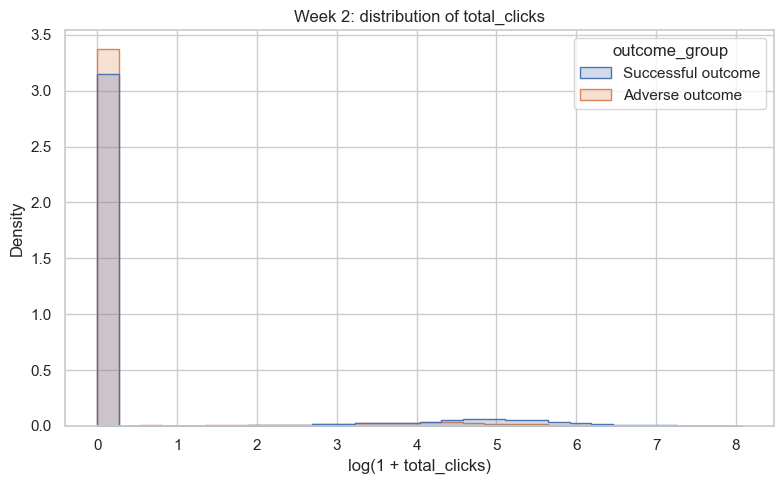

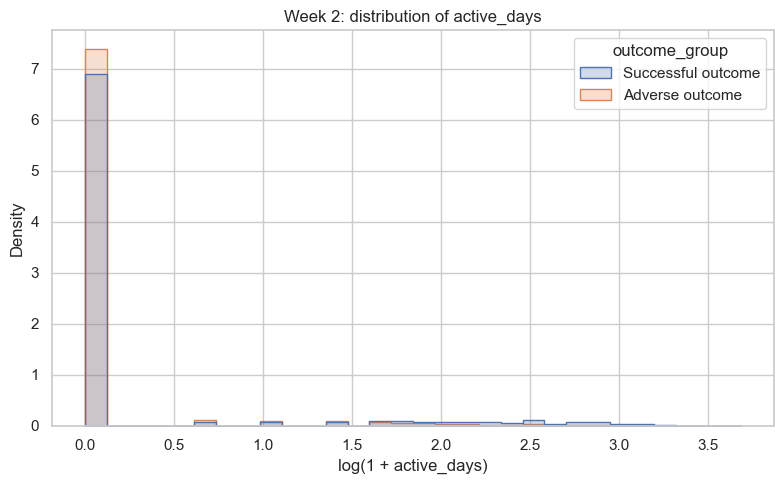

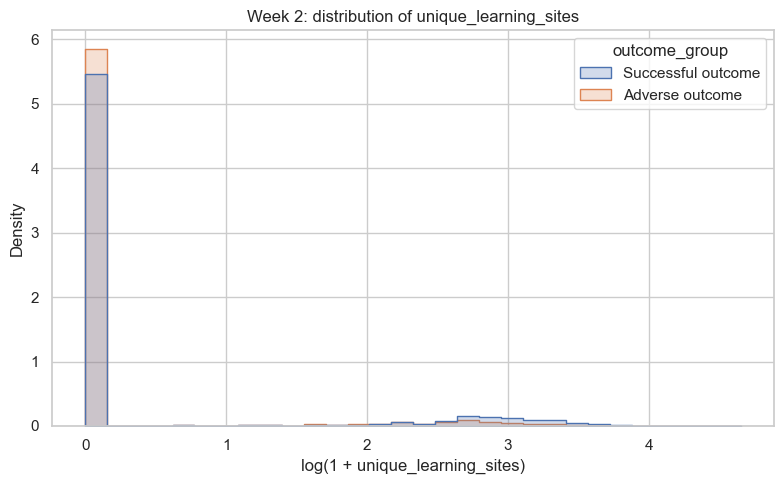

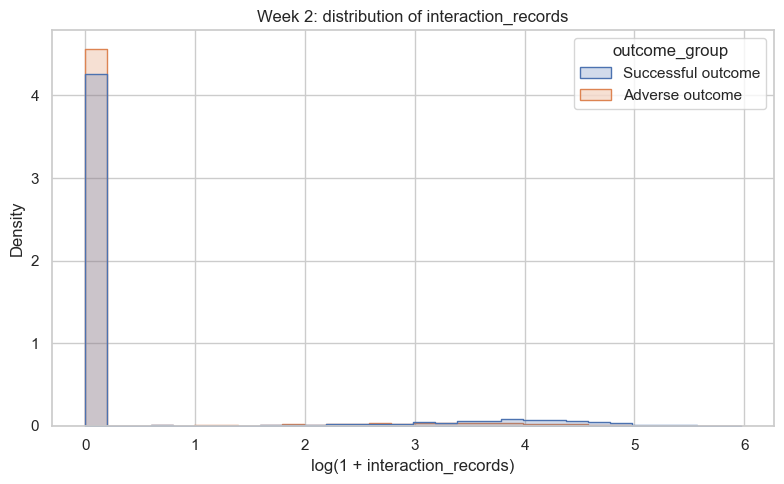

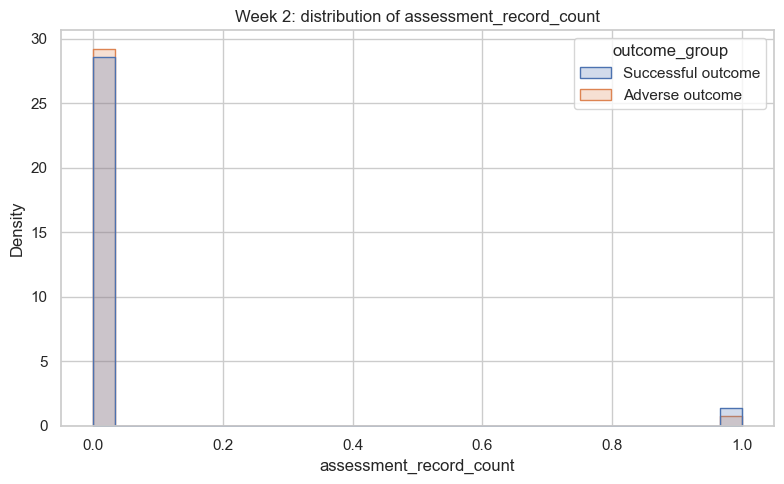

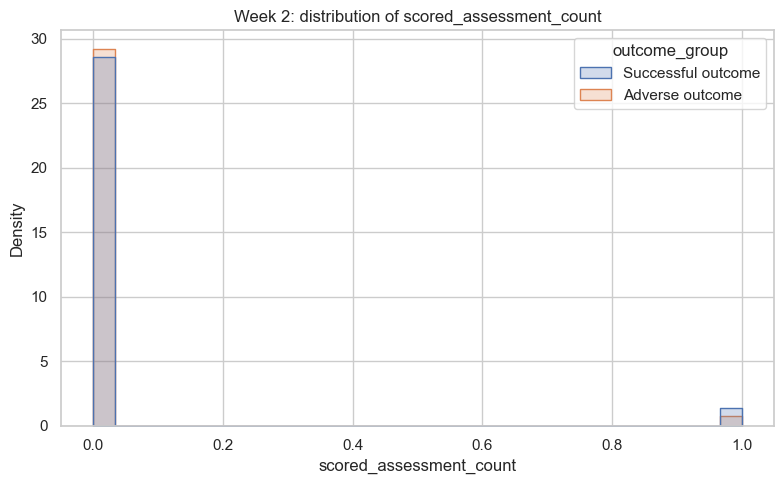

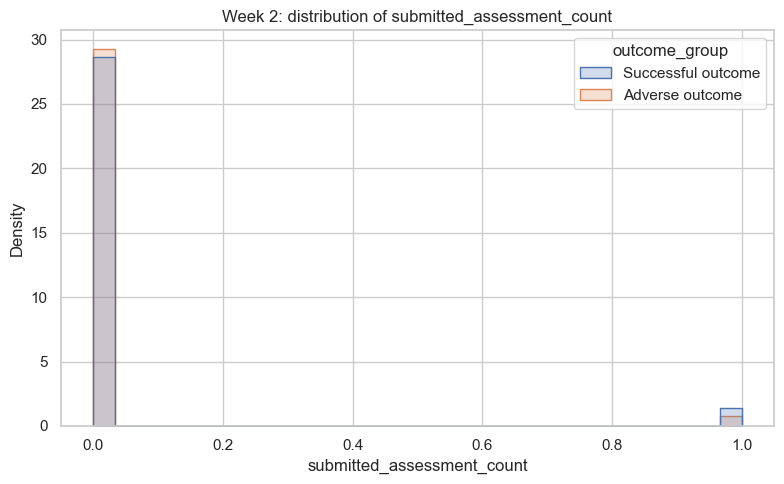

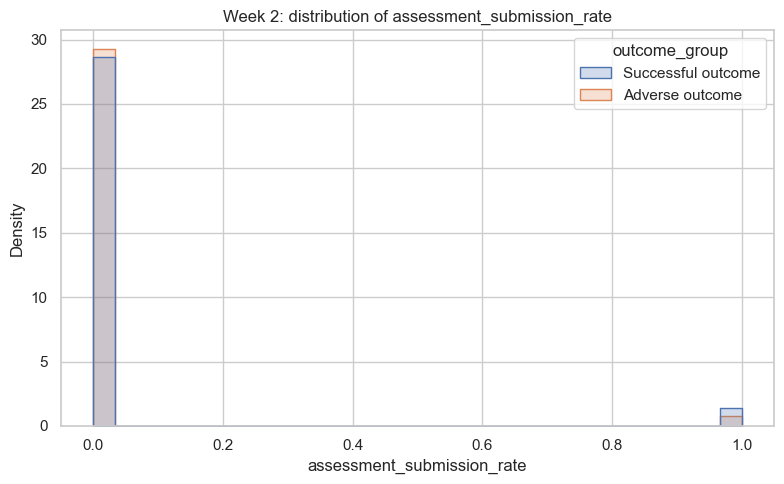

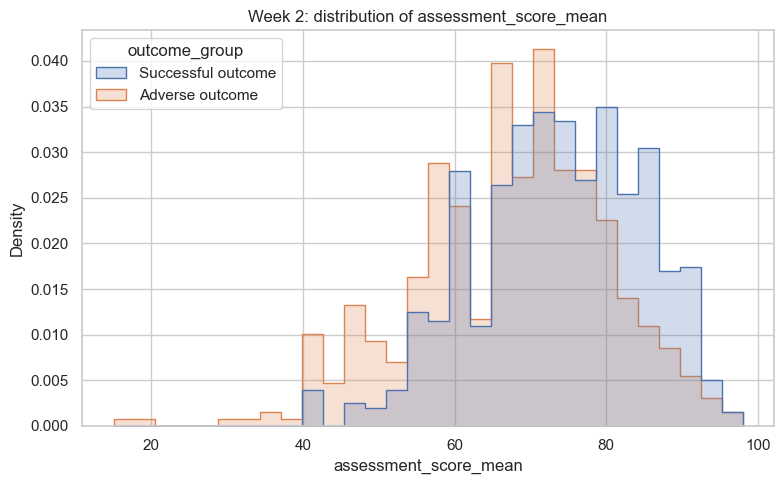

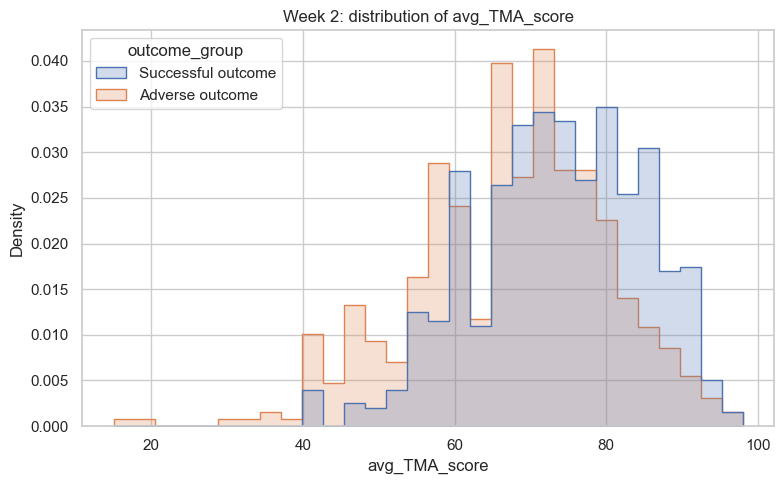

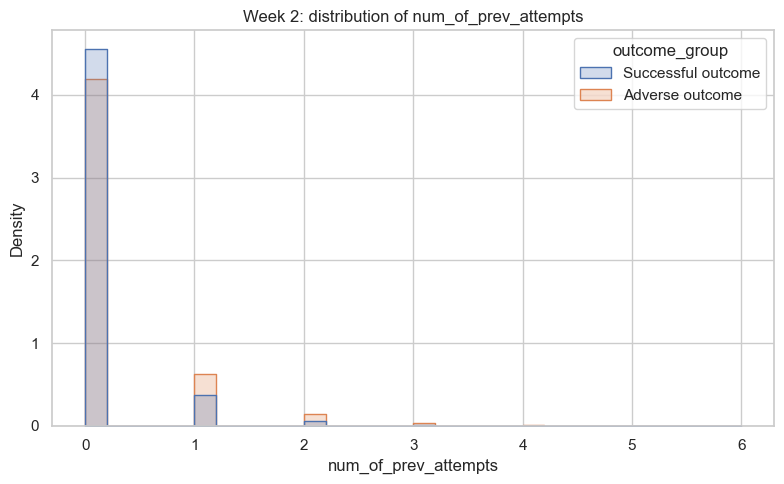

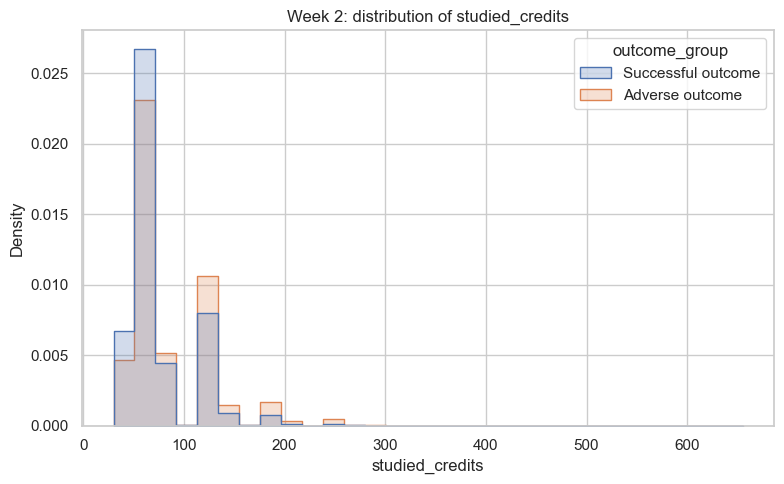

Numerical features selected for Week 4:
['total_clicks', 'active_days', 'unique_learning_sites', 'interaction_records', 'assessment_record_count', 'scored_assessment_count', 'submitted_assessment_count', 'assessment_submission_rate', 'assessment_score_mean', 'avg_TMA_score', 'avg_CMA_score', 'num_of_prev_attempts', 'studied_credits']


,count,mean,std,min,25%,50%,75%,max,window
total_clicks,32593.0,32.363452,157.153727,0.0,0.0,0.0,0.0,4602.0,Week 4
active_days,32593.0,1.592213,5.339939,0.0,0.0,0.0,0.0,53.0,Week 4
unique_learning_sites,32593.0,2.347375,7.294129,0.0,0.0,0.0,0.0,106.0,Week 4
interaction_records,32593.0,8.858068,33.063100,0.0,0.0,0.0,0.0,528.0,Week 4
assessment_record_count,32593.0,0.676311,0.526165,0.0,0.0,1.0,1.0,2.0,Week 4
scored_assessment_count,32593.0,0.675421,0.526346,0.0,0.0,1.0,1.0,2.0,Week 4
submitted_assessment_count,32593.0,0.657472,0.531126,0.0,0.0,1.0,1.0,2.0,Week 4
assessment_submission_rate,32593.0,0.628985,0.483060,0.0,0.0,1.0,1.0,1.0,Week 4
assessment_score_mean,21072.0,72.157057,21.983556,0.0,64.0,76.0,87.0,100.0,Week 4
avg_TMA_score,17741.0,72.969449,21.129396,0.0,65.0,76.0,86.0,100.0,Week 4


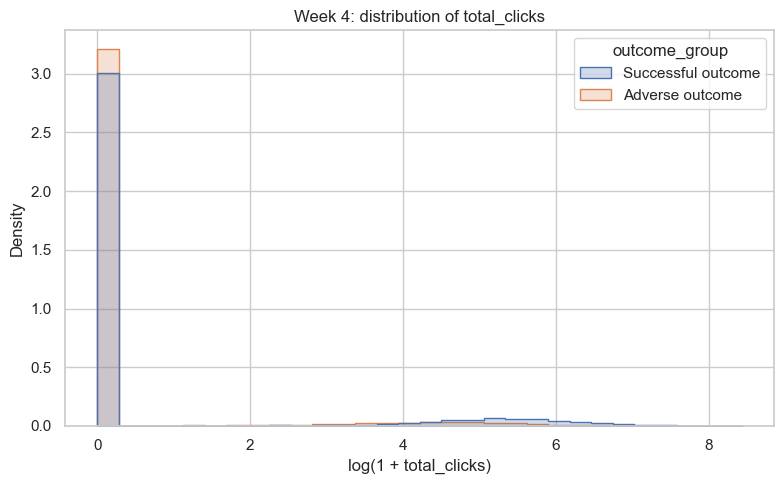

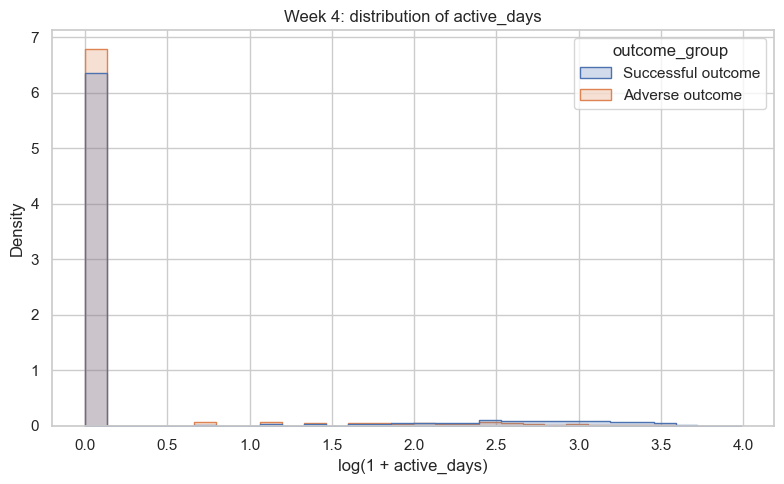

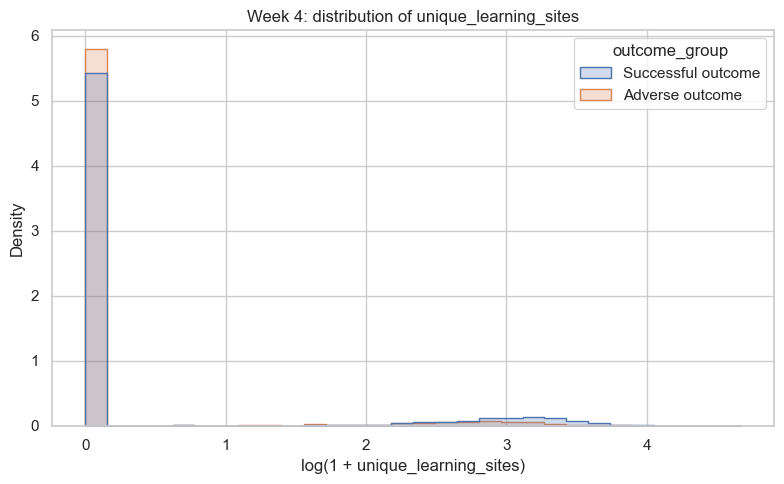

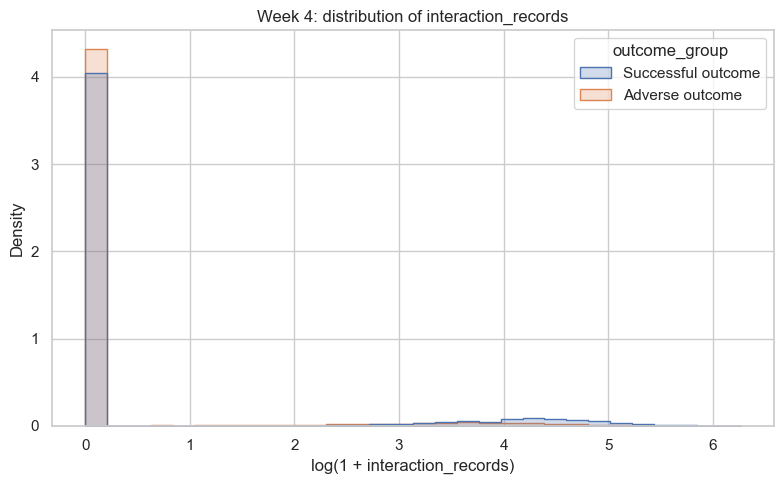

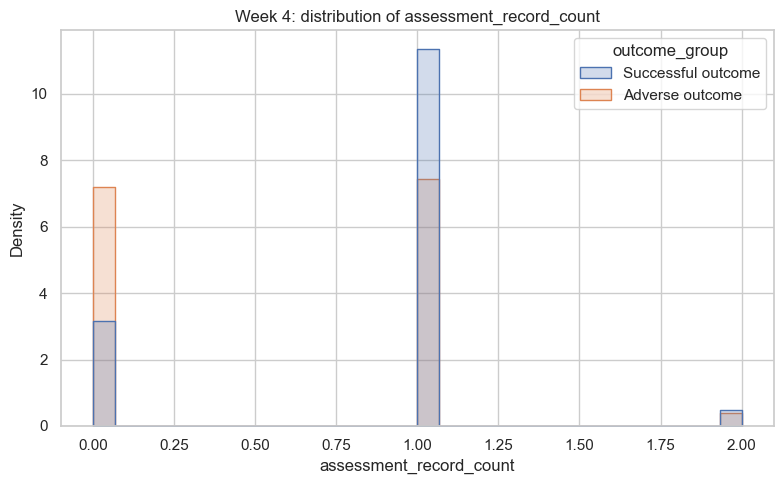

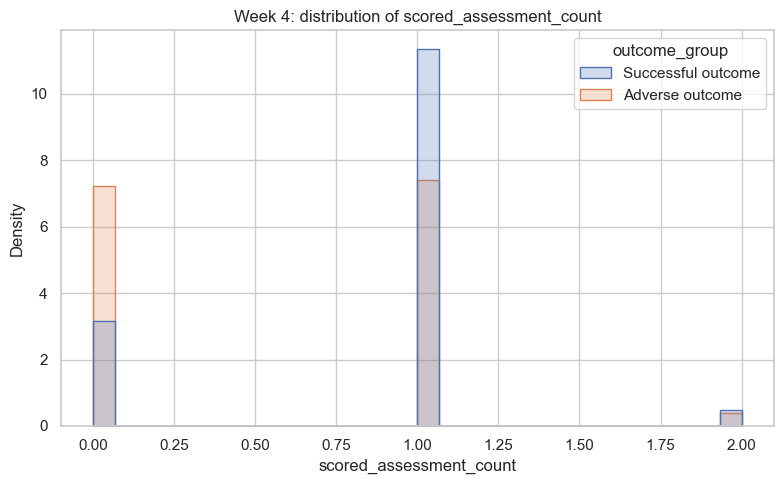

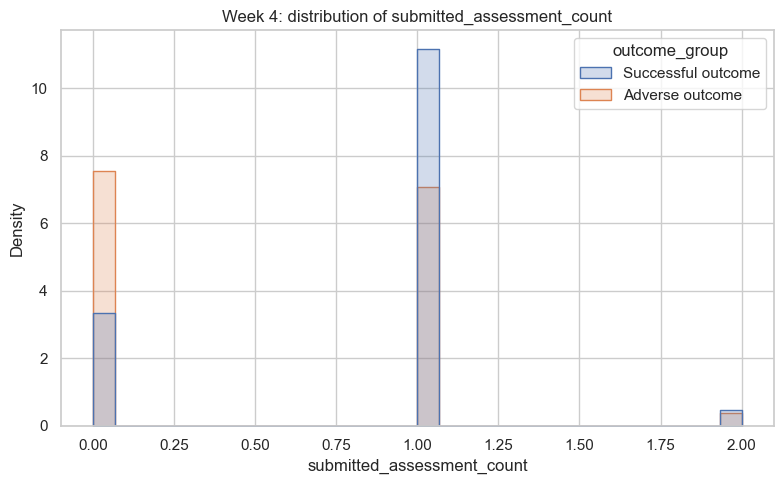

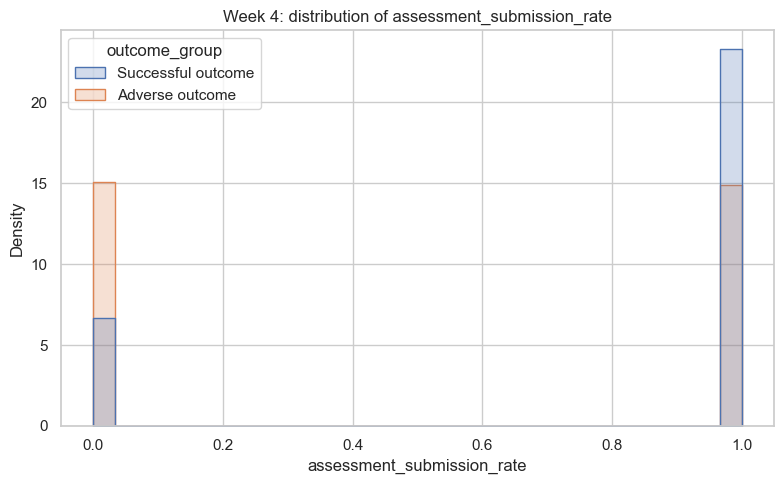

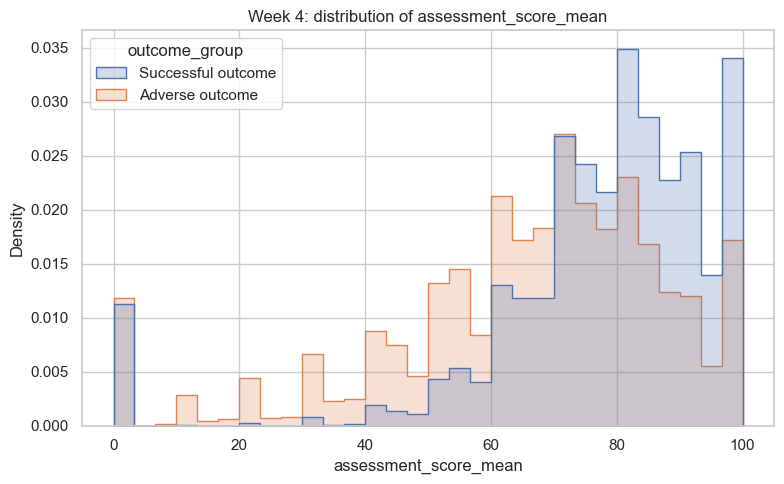

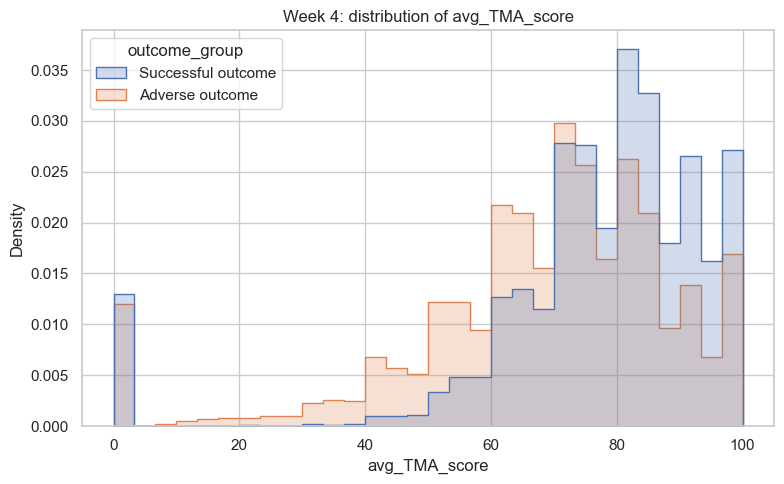

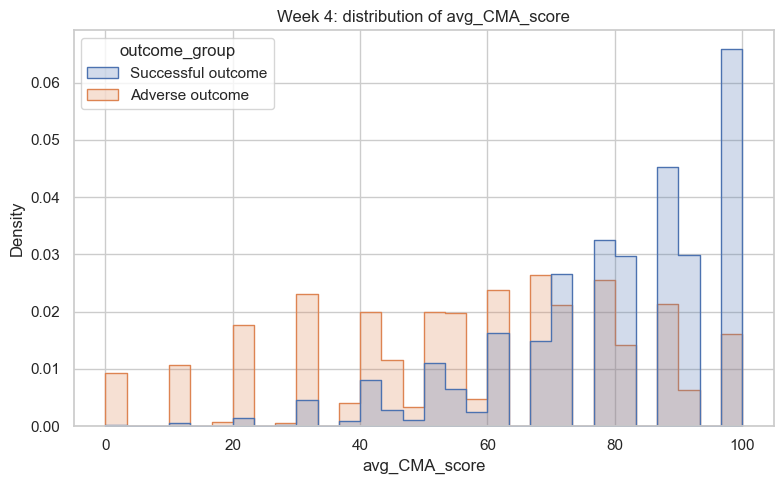

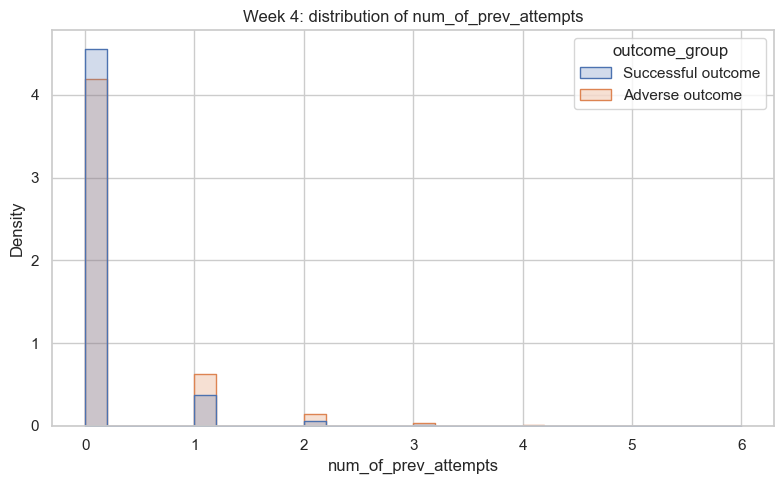

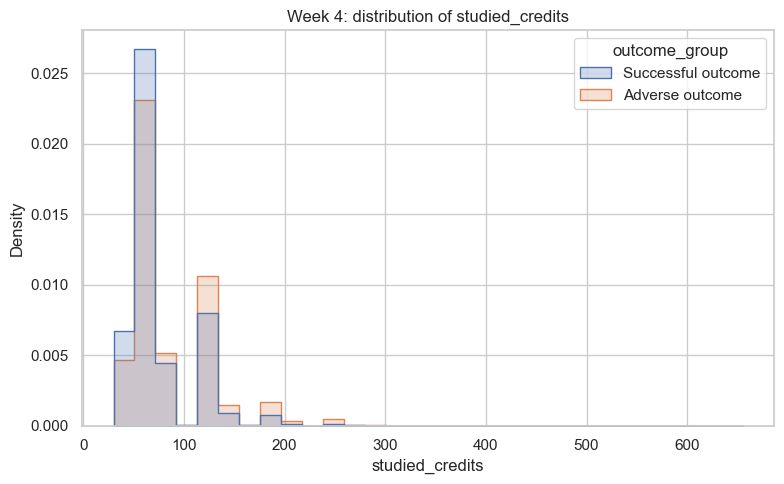

Numerical features selected for Week 6:
['total_clicks', 'active_days', 'unique_learning_sites', 'interaction_records', 'assessment_record_count', 'scored_assessment_count', 'submitted_assessment_count', 'assessment_submission_rate', 'assessment_score_mean', 'avg_TMA_score', 'avg_CMA_score', 'num_of_prev_attempts', 'studied_credits']


,count,mean,std,min,25%,50%,75%,max,window
total_clicks,32593.0,41.322401,201.075627,0.0,0.0,0.0,0.0,6107.0,Week 6
active_days,32593.0,2.111865,7.089200,0.0,0.0,0.0,0.0,67.0,Week 6
unique_learning_sites,32593.0,2.623569,8.091104,0.0,0.0,0.0,0.0,112.0,Week 6
interaction_records,32593.0,11.325990,42.263627,0.0,0.0,0.0,0.0,652.0,Week 6
assessment_record_count,32593.0,0.893045,0.661627,0.0,0.0,1.0,1.0,2.0,Week 6
scored_assessment_count,32593.0,0.891787,0.661909,0.0,0.0,1.0,1.0,2.0,Week 6
submitted_assessment_count,32593.0,0.869420,0.667148,0.0,0.0,1.0,1.0,2.0,Week 6
assessment_submission_rate,32593.0,0.703096,0.456599,0.0,0.0,1.0,1.0,1.0,Week 6
assessment_score_mean,23499.0,73.791119,21.206512,0.0,66.0,78.0,88.0,100.0,Week 6
avg_TMA_score,22405.0,74.819482,20.664723,0.0,67.0,78.5,88.0,100.0,Week 6


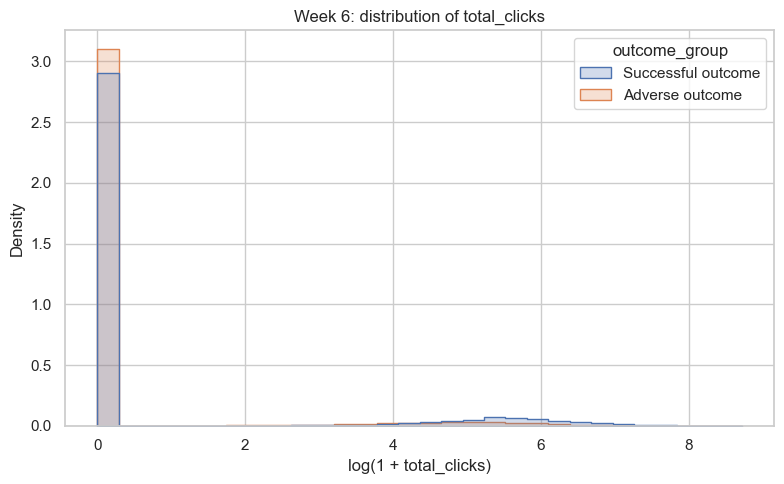

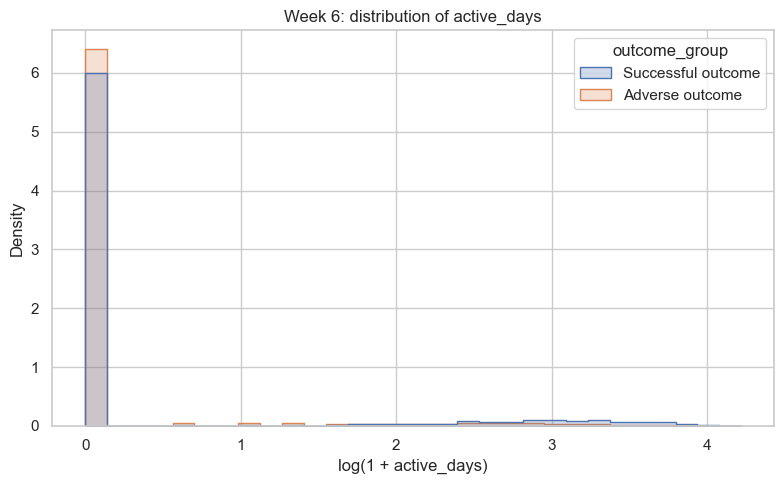

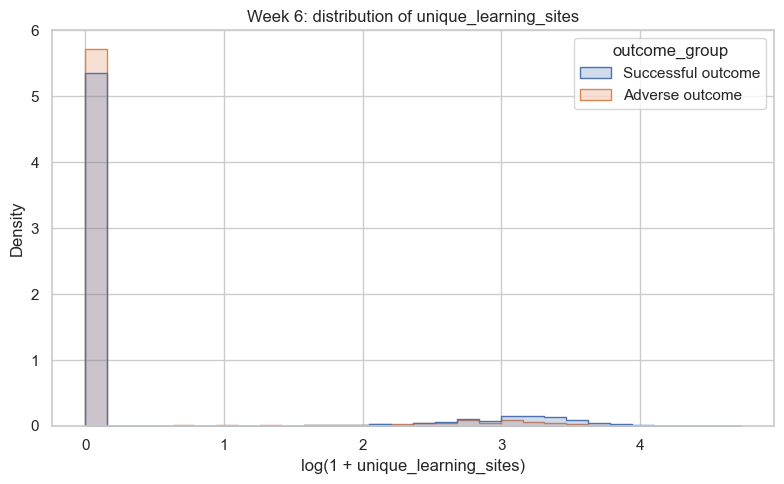

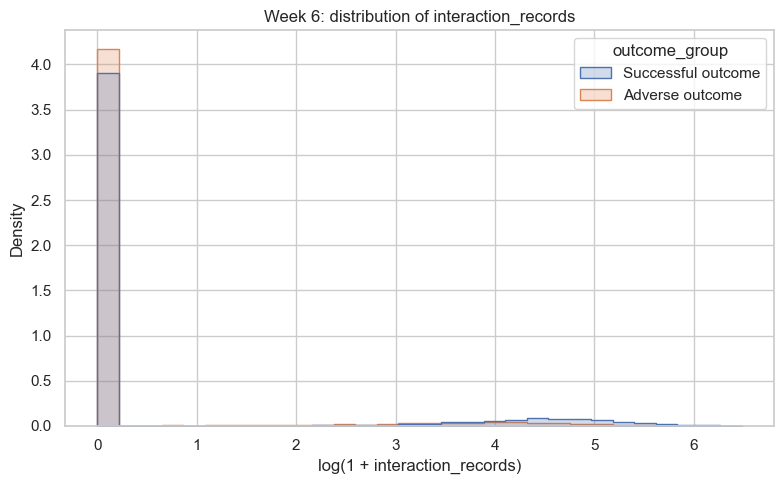

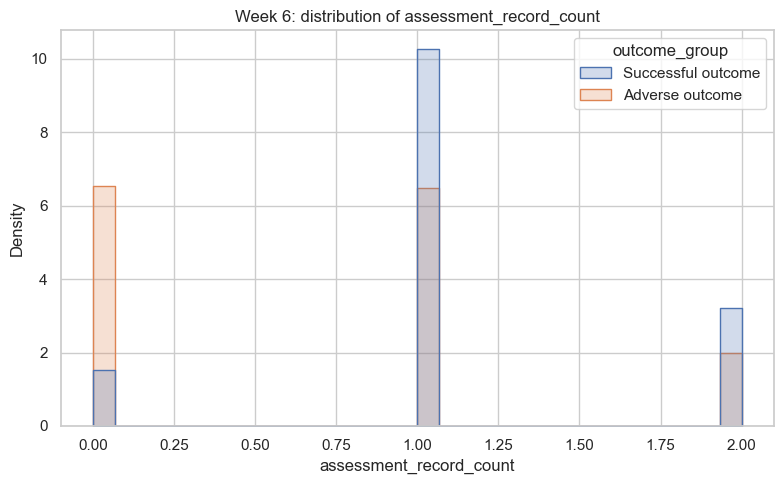

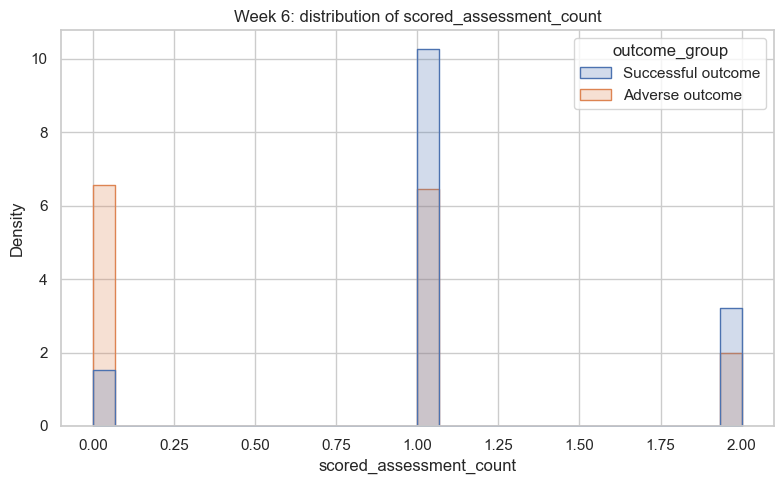

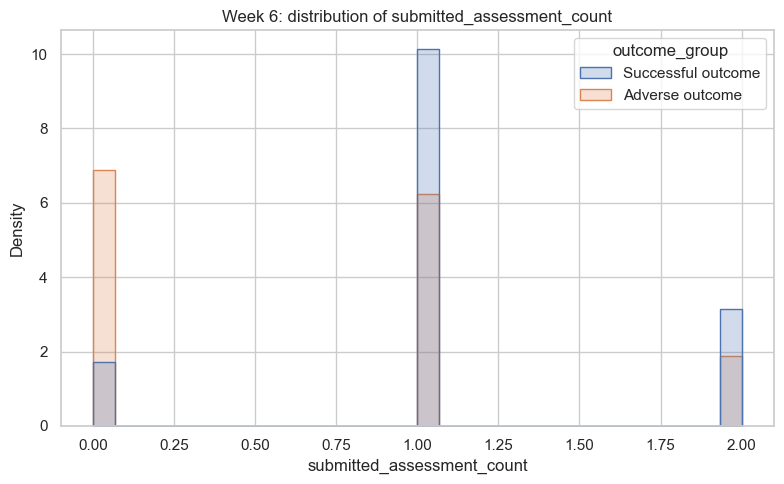

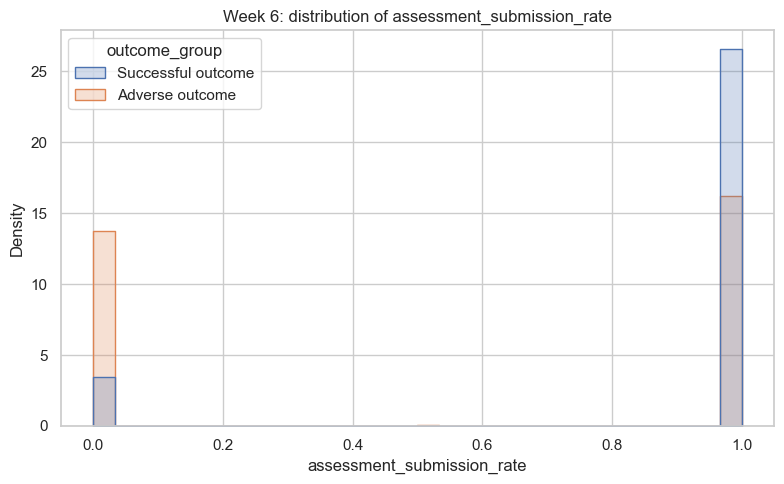

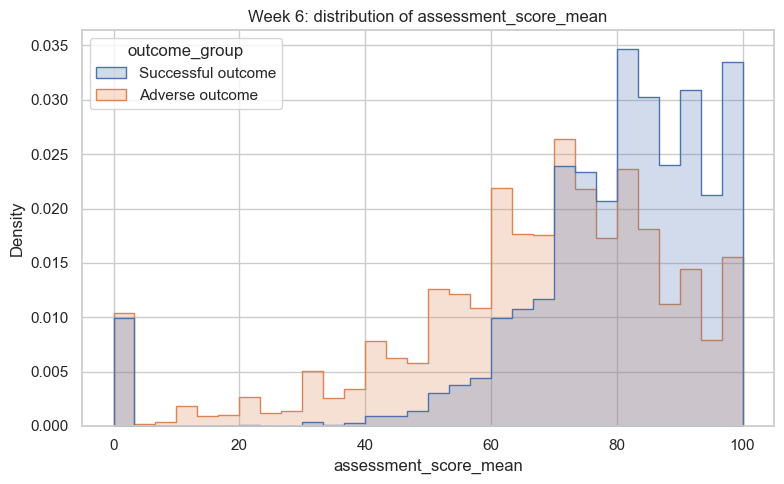

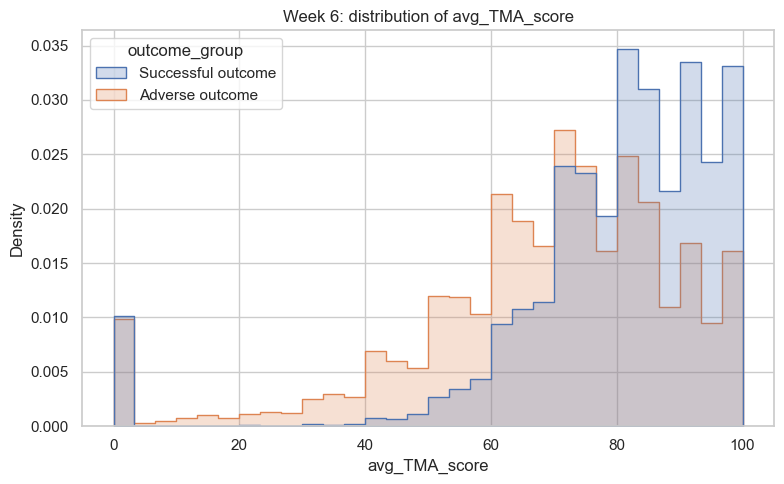

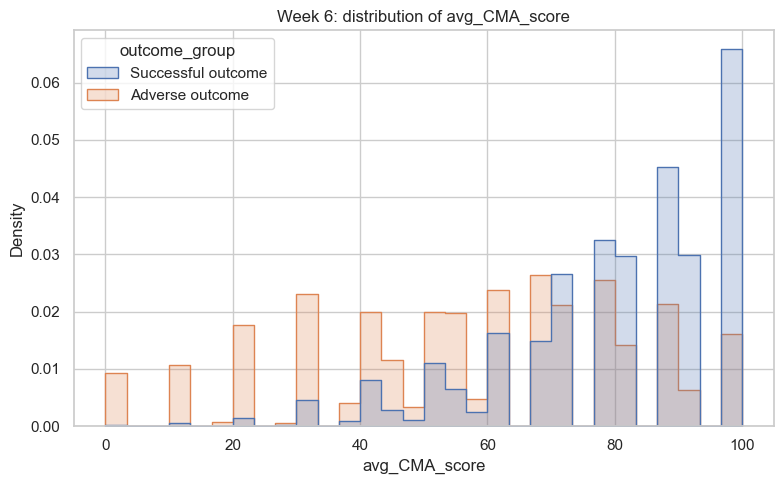

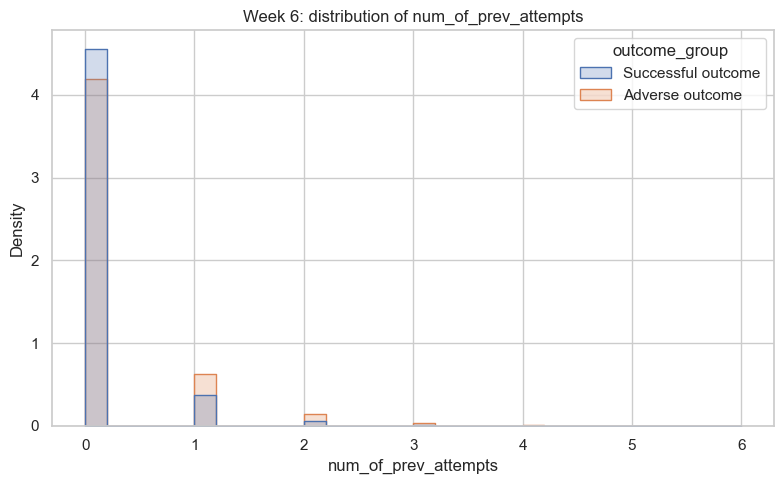

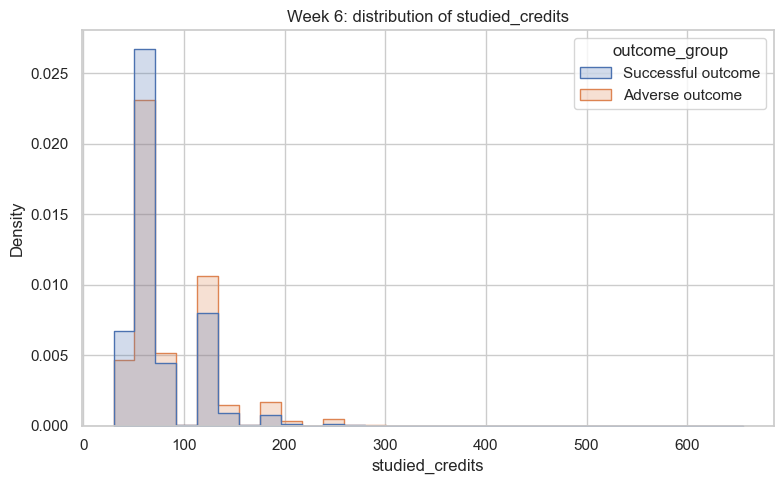

Univariate analysis completed for Weeks 2, 4 and 6.


In [23]:
# List the numerical features to examine
candidate_features = [
    "total_clicks",
    "active_days",
    "unique_learning_sites",
    "interaction_records",
    "assessment_record_count",
    "scored_assessment_count",
    "submitted_assessment_count",
    "assessment_submission_rate",
    "assessment_score_mean",
    "avg_TMA_score",
    "avg_CMA_score",
    "num_of_prev_attempts",
    "studied_credits"
]

# Create an empty list for all window statistics
all_statistics = []

# Analyse Week 2, Week 4 and Week 6 separately
for window, data in analytical_datasets.items():

    # Select numerical features in the current window
    numeric_features = [
        column
        for column in candidate_features
        if column in data.columns
        and pd.api.types.is_numeric_dtype(data[column])
    ]

    # Identify count features for log transformation
    log_features = [
        column
        for column in [
            "total_clicks",
            "active_days",
            "unique_learning_sites",
            "interaction_records"
        ]
        if column in numeric_features
    ]

    # Show which features are being analysed
    print(f"Numerical features selected for Week {window}:")
    print(numeric_features)

    # Calculate descriptive statistics
    window_statistics = data[numeric_features].describe().T

    # Add the prediction window to the results
    window_statistics["window"] = f"Week {window}"

    # Display the statistics for this window
    display(window_statistics)

    # Store the statistics for all windows
    all_statistics.append(window_statistics)

    # Save the statistics for this window
    window_statistics.to_csv(
        eda_folder / f"numeric_descriptive_statistics_week_{window}.csv"
    )

    # Create one graph for each numerical feature
    for column in numeric_features:

        # Copy the feature and target columns
        plot_data = data[[column, "target"]].copy()

        # Convert target values into readable labels
        plot_data["outcome_group"] = plot_data["target"].map({
            0: "Adverse outcome",
            1: "Successful outcome"
        })

        # Use the original feature values
        plot_column = column
        x_label = column

        # Apply log transformation to count features
        if column in log_features:

            # Create transformed values for the graph only
            plot_data["plot_value"] = np.log1p(plot_data[column])

            # Use the transformed values in the graph
            plot_column = "plot_value"

            # Update the x-axis label
            x_label = f"log(1 + {column})"

        # Create the graph
        plt.figure(figsize=(8, 5))

        # Plot the feature by outcome group
        sns.histplot(
            data=plot_data,
            x=plot_column,
            hue="outcome_group",
            bins=30,
            element="step",
            stat="density",
            common_norm=False
        )

        # Add the graph title
        plt.title(f"Week {window}: distribution of {column}")

        # Add the x-axis label
        plt.xlabel(x_label)

        # Add the y-axis label
        plt.ylabel("Density")

        # Arrange the graph neatly
        plt.tight_layout()

        # Save the graph
        plt.savefig(
            eda_folder / f"week_{window}_distribution_{column}.png",
            dpi=300,
            bbox_inches="tight"
        )

        # Display the graph
        plt.show()

# Combine the statistics from all three windows
all_statistics_df = pd.concat(all_statistics)

# Save the combined statistics
all_statistics_df.to_csv(
    eda_folder / "numeric_descriptive_statistics_all_windows.csv"
)

# Keep Week 6 available for later cells that specifically use Week 6
week6 = analytical_datasets[6].copy()

# Add readable outcome labels for later Week 6 plots
week6["outcome_group"] = week6["target"].map({
    0: "Adverse outcome",
    1: "Successful outcome"
})

print("Univariate analysis completed for Weeks 2, 4 and 6.")
 


### Meaning of the numerical analysis across prediction windows

The numerical features were examined across Weeks 2, 4 and 6 to understand how the available information changes before model training. This directly supports the research design because the study compares prediction performance at these three fixed time points.

The engagement features increase as the window becomes longer. Mean total clicks increase from 21.03 in Week 2 to 32.36 in Week 4 and 41.32 in Week 6. Mean active days increase from 0.96 to 1.59 and then 2.11. Mean interaction records increase from 5.77 to 8.86 and then 11.33. This shows that later windows contain more recorded student activity.

The engagement variables are strongly concentrated at zero. Their medians and 75th-percentile values are zero, while their maximum values are much higher. This indicates that many students had no recorded activity in the constructed features, while a smaller group had much higher engagement. The distributions are therefore right-skewed.

Assessment information also increases across the windows. The mean assessment record count rises from 0.04 in Week 2 to 0.68 in Week 4 and 0.89 in Week 6. The number of available assessment scores also increases. This confirms that Week 2 contains much less assessment information than Weeks 4 and 6.

The **count** value for the score variables shows the number of non-missing scores, not the total number of students. Therefore, the Week 2 assessment score distributions describe only the students who had an available score by that early cutoff.

The assessment score graphs show a clearer difference between the outcome groups than most of the engagement graphs. Successful outcome students are more concentrated at higher assessment and TMA scores, while adverse outcome students are more common at lower scores. However, the distributions still overlap, so these variables cannot perfectly classify the outcomes by themselves.

The previous attempts and studied credits variables remain stable across the three windows because they are student or course background variables rather than cumulative engagement measures. Their graphs show considerable overlap between successful and adverse outcomes.

Overall, the EDA suggests that assessment scores, assessment participation and engagement activity may provide useful predictive information. But these are preliminary associations only. The EDA does not determine which prediction window is best or whether the hypotheses are supported. Those questions require the later model comparison using Weeks 2, 4 and 6.


## 7. Bivariate analysis: numerical features and outcome across prediction windows
The purpose of this section is to compare each numerical feature with the final outcome. The analysis examines whether successful and adverse outcome groups show different values for engagement, assessment and background features.

The comparison is performed separately for Weeks 2, 4 and 6. This helps identify whether the differences between outcome groups become clearer as more information becomes available. Bivariate analysis can reveal possible relationships between variables, but it does not prove causation or confirm predictive performance (Ozdemir, 2016).



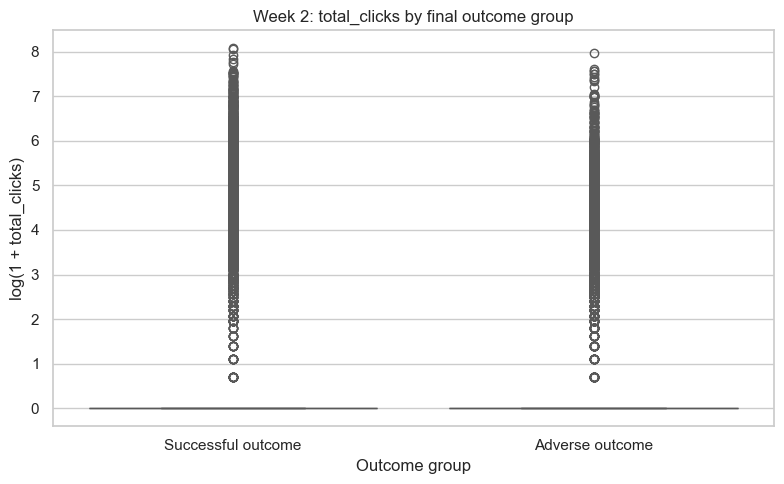

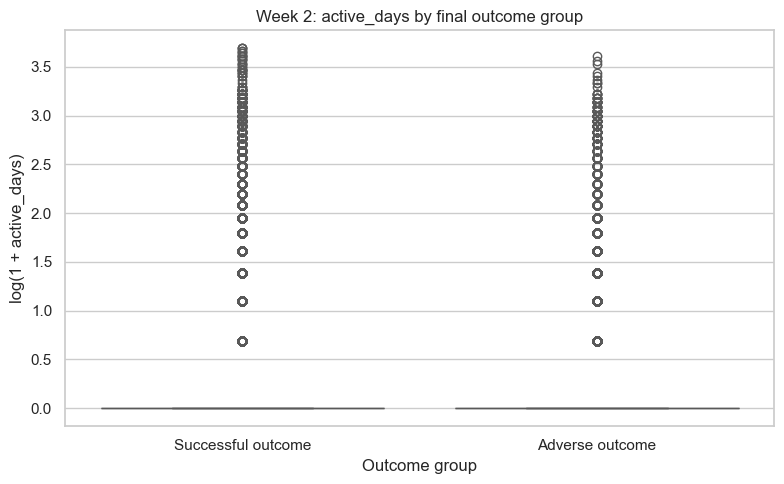

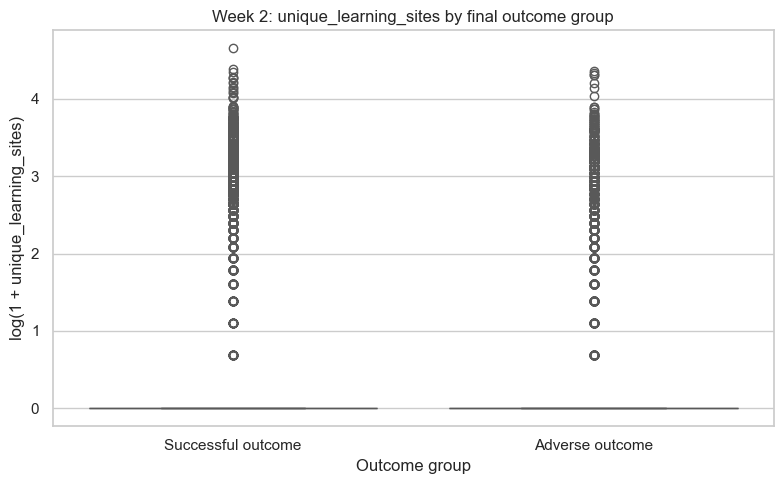

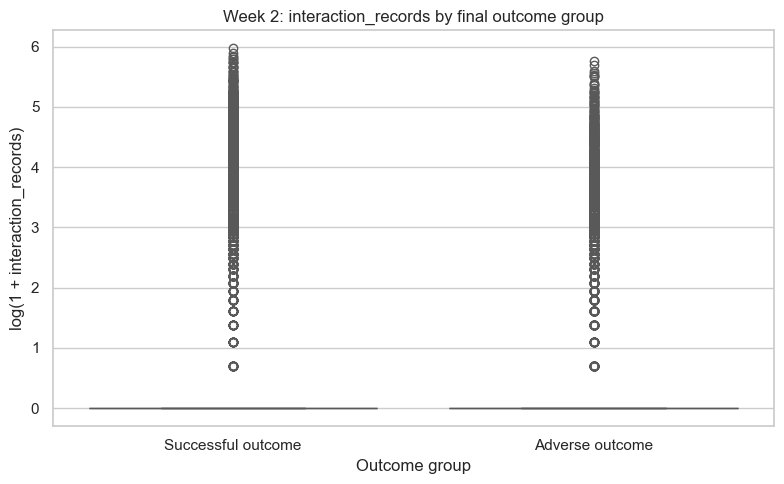

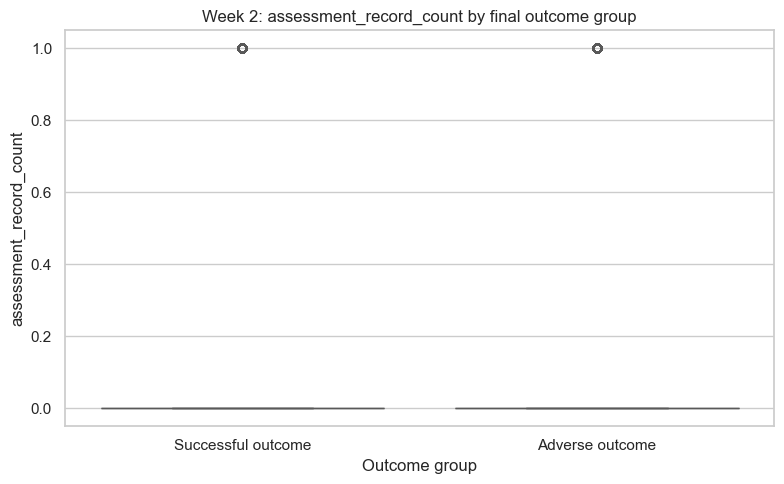

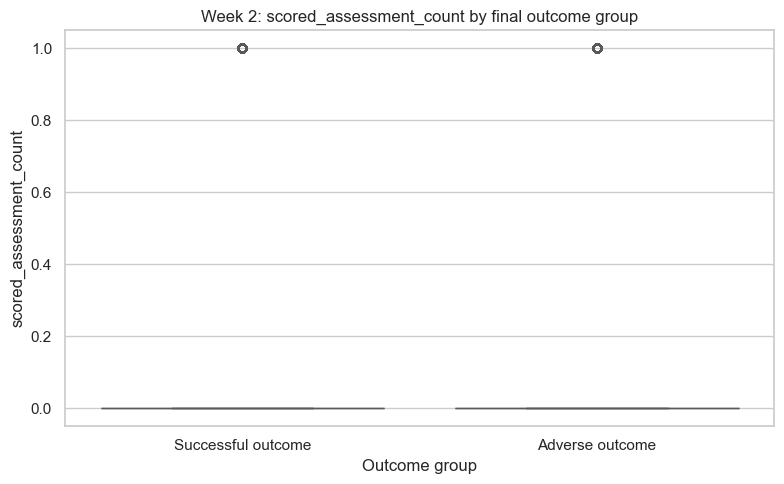

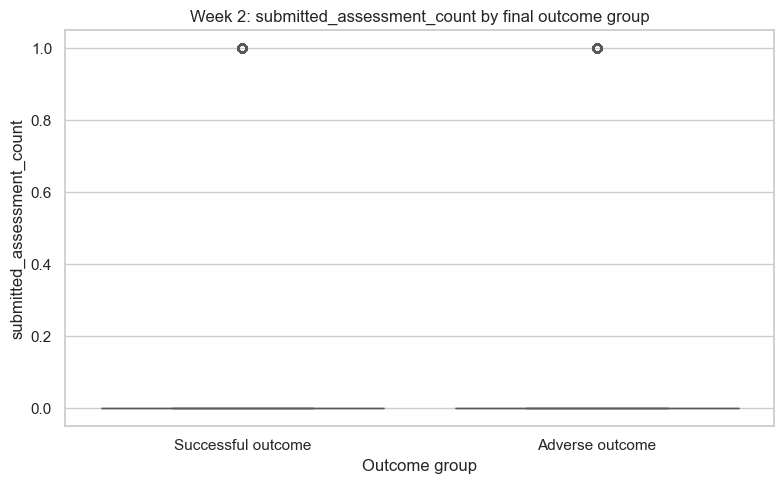

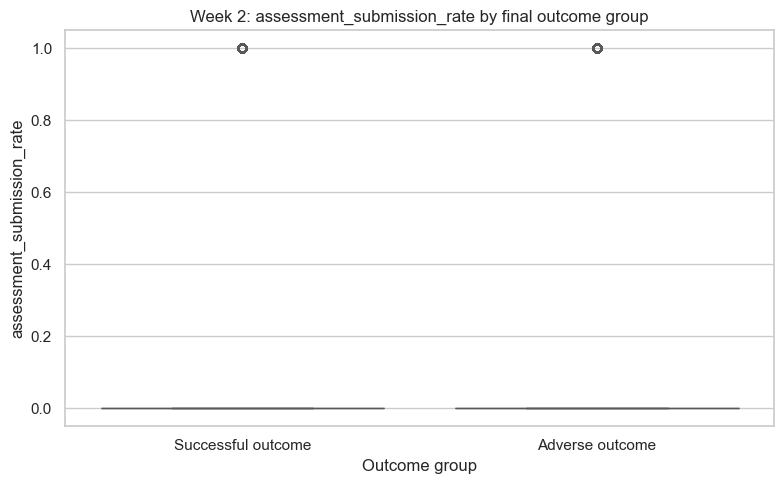

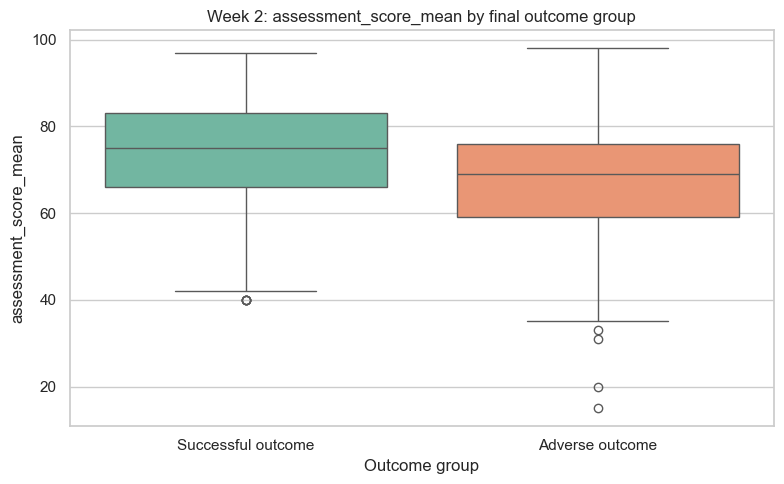

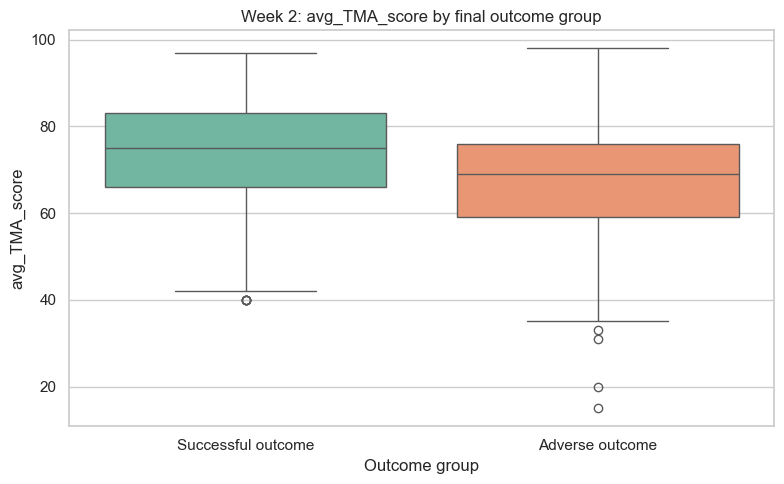

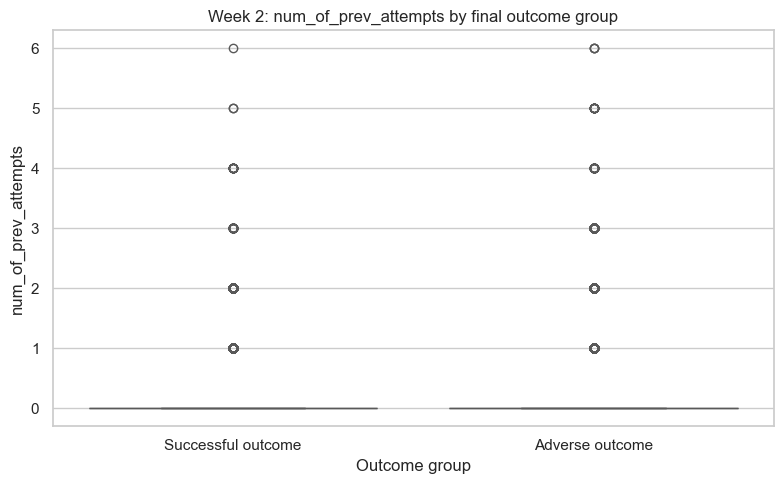

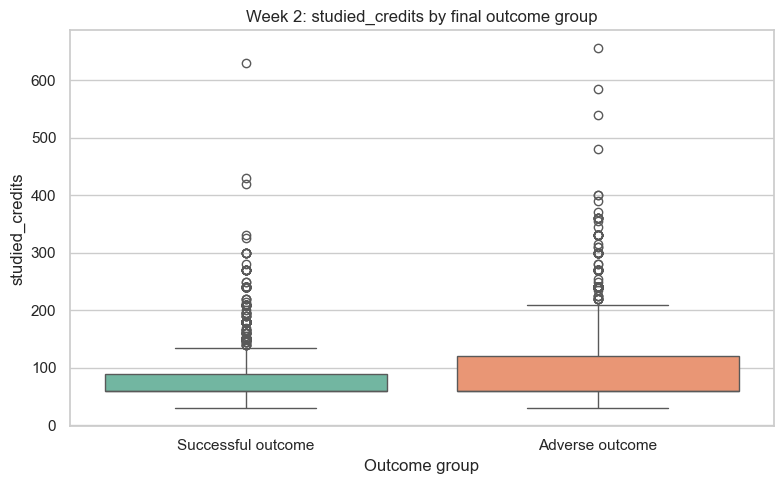

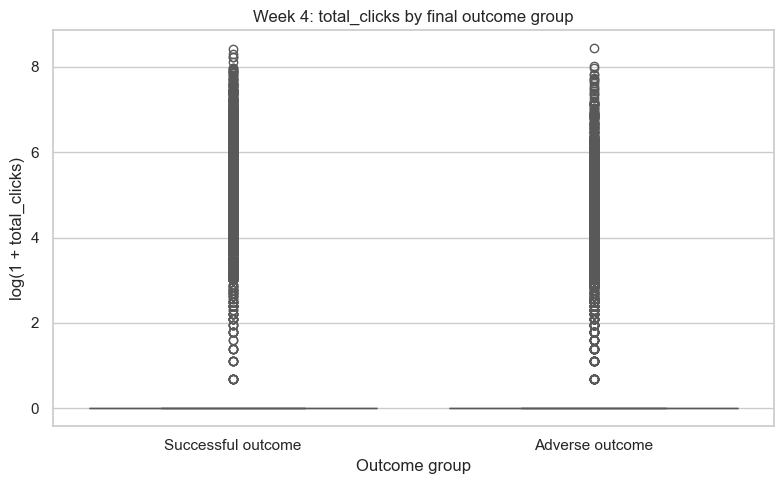

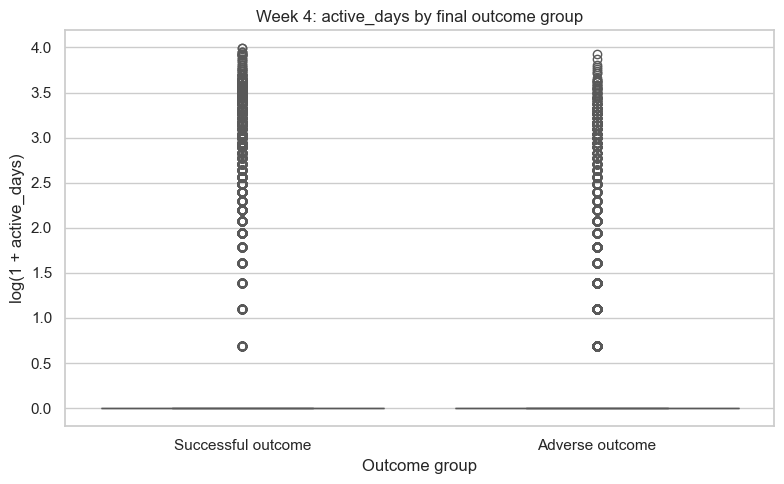

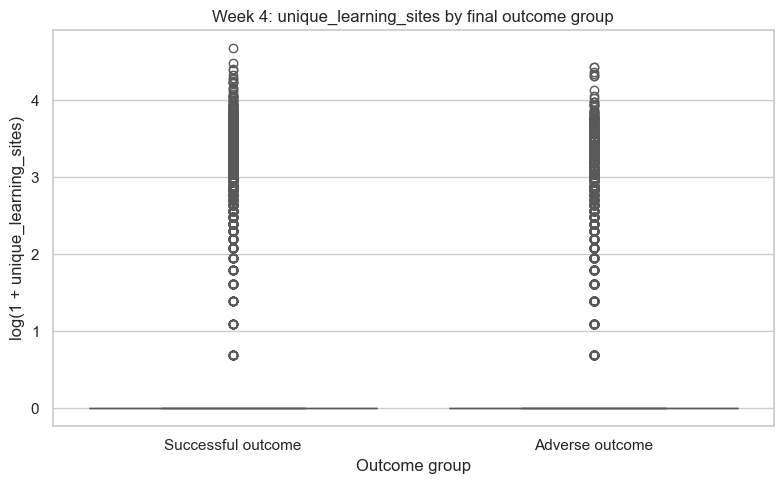

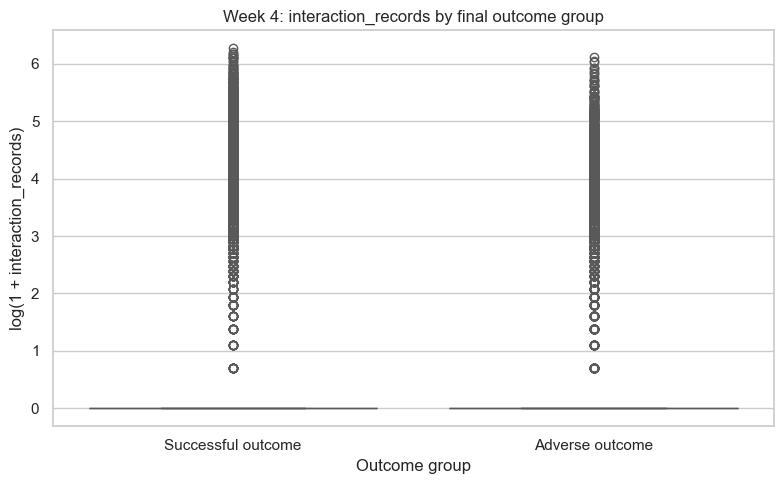

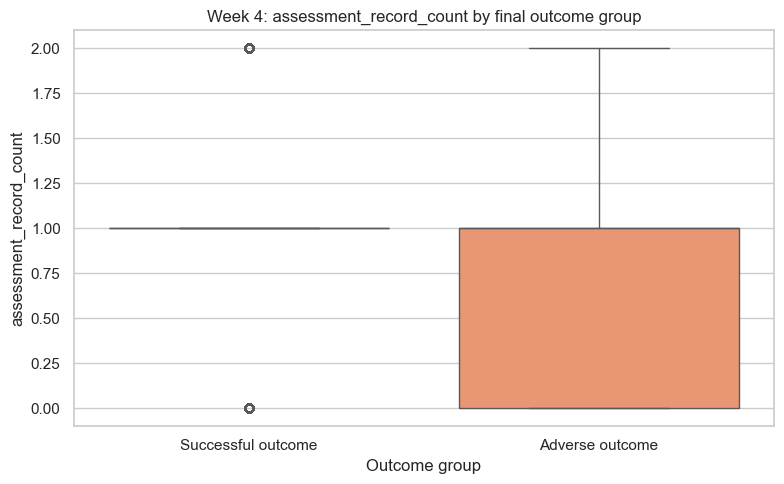

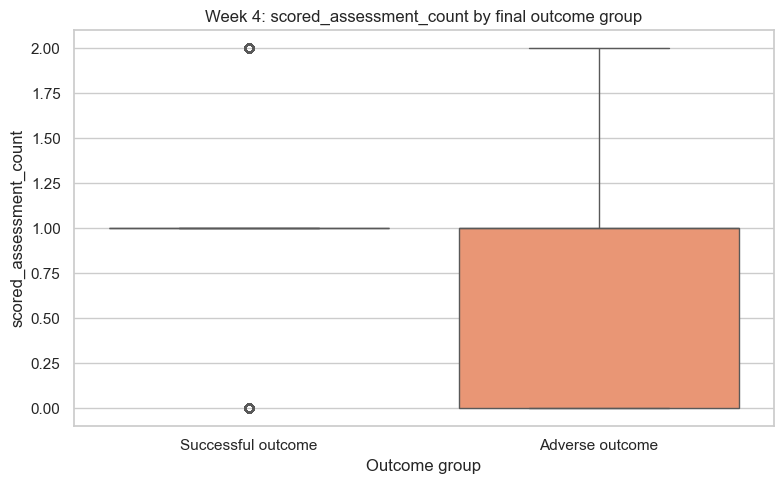

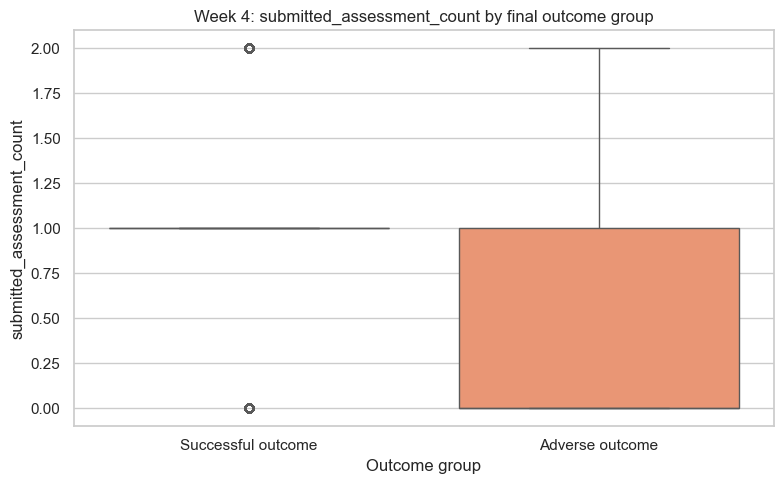

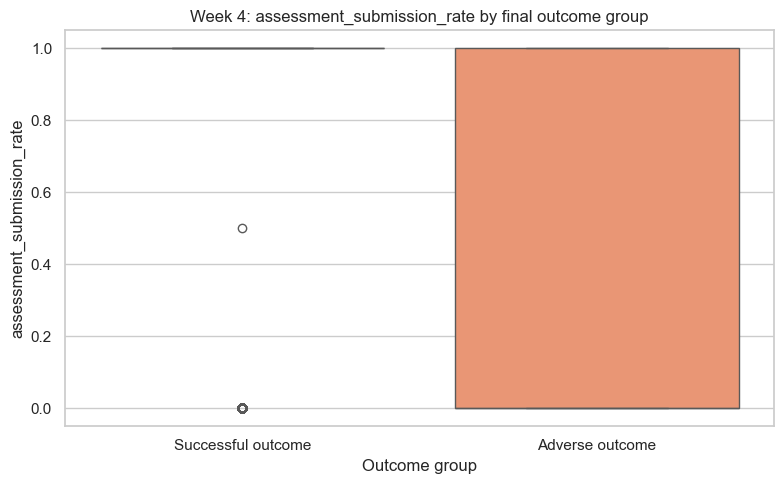

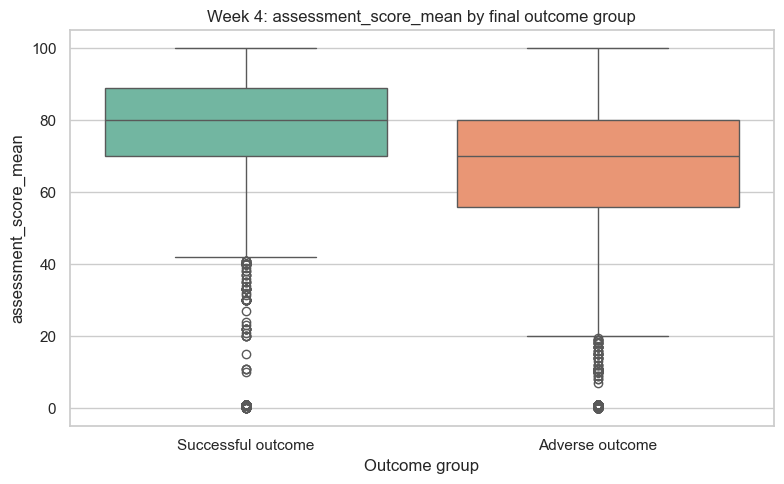

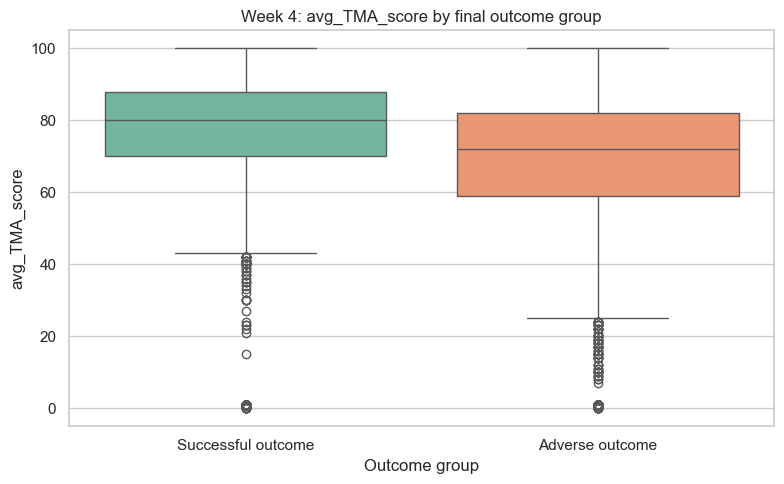

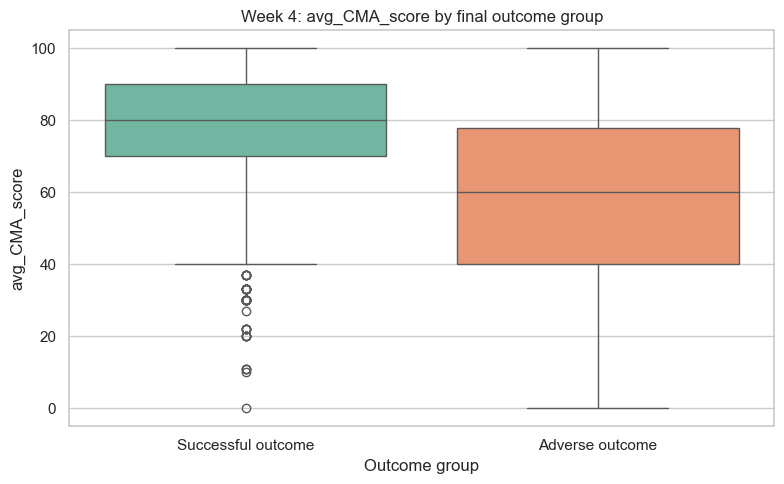

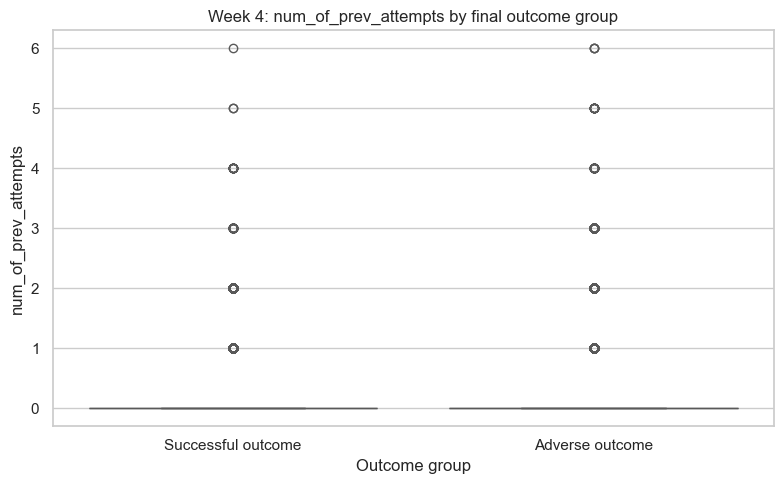

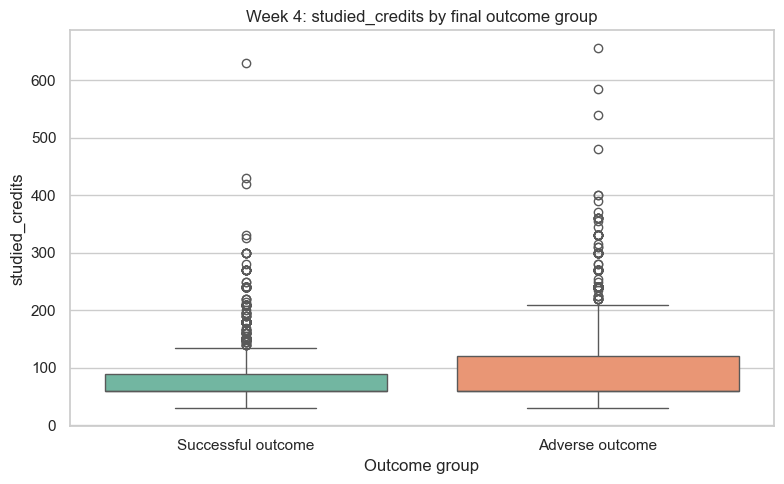

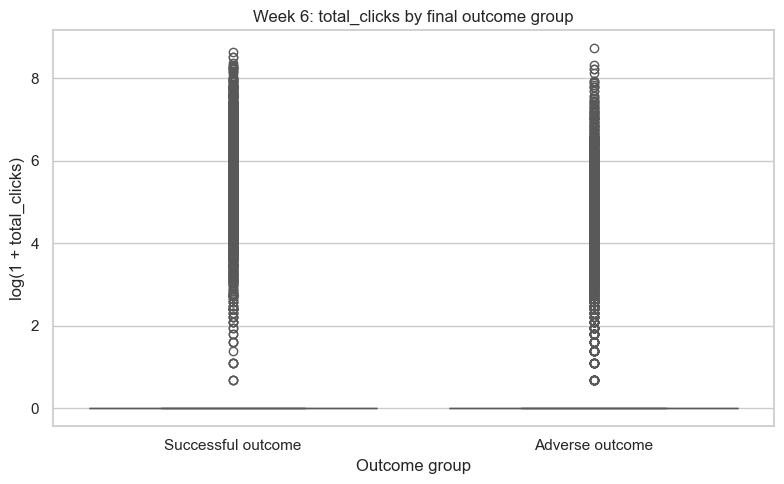

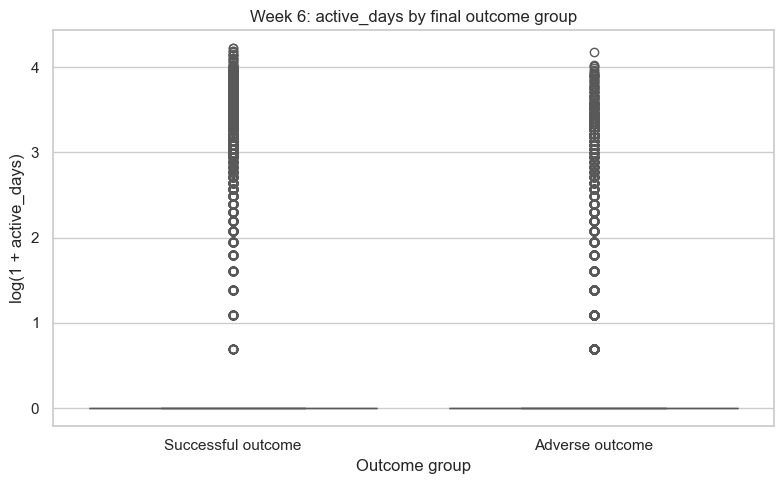

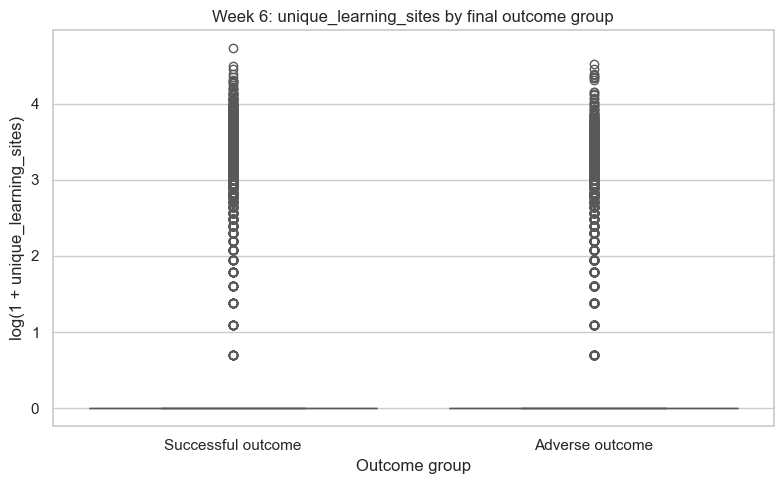

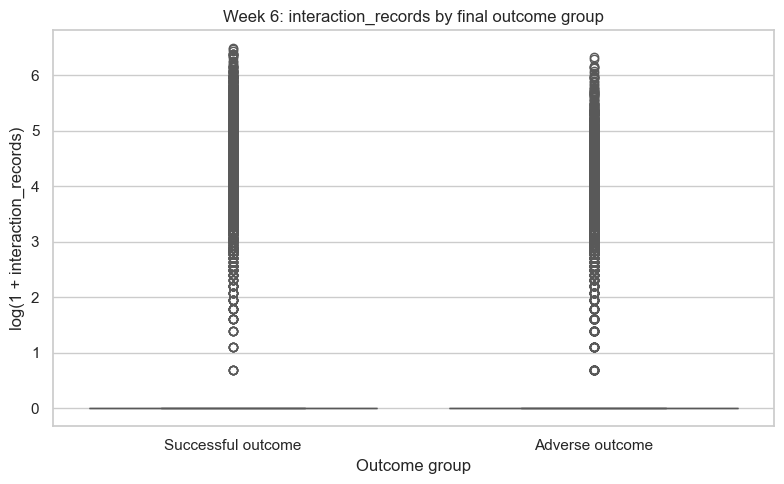

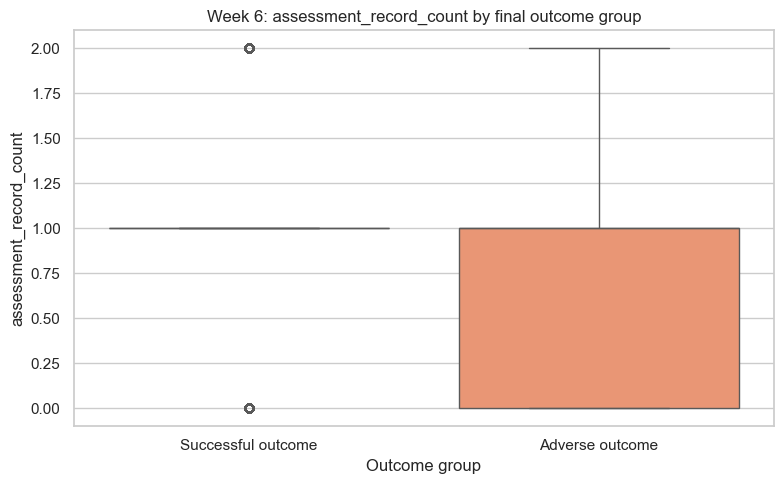

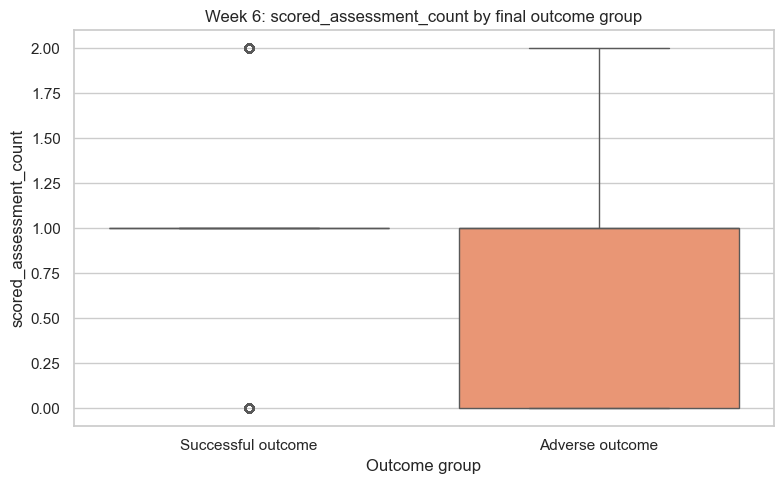

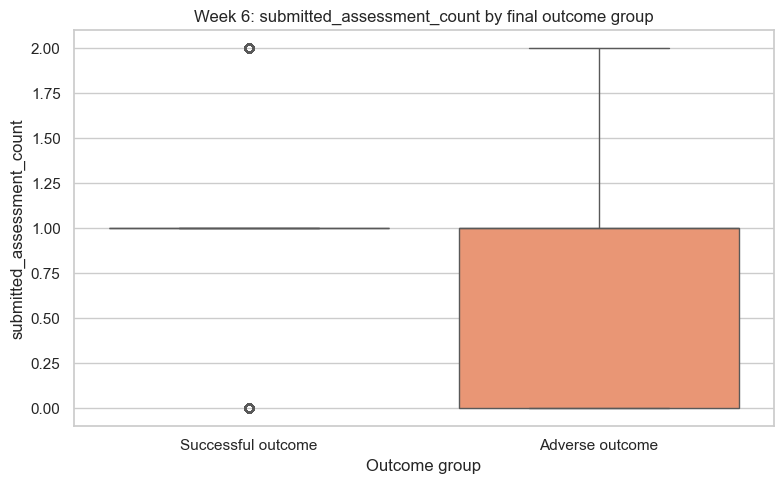

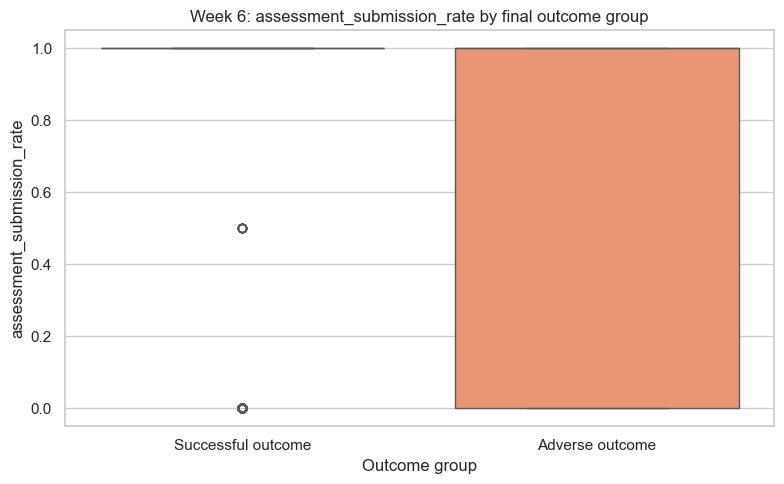

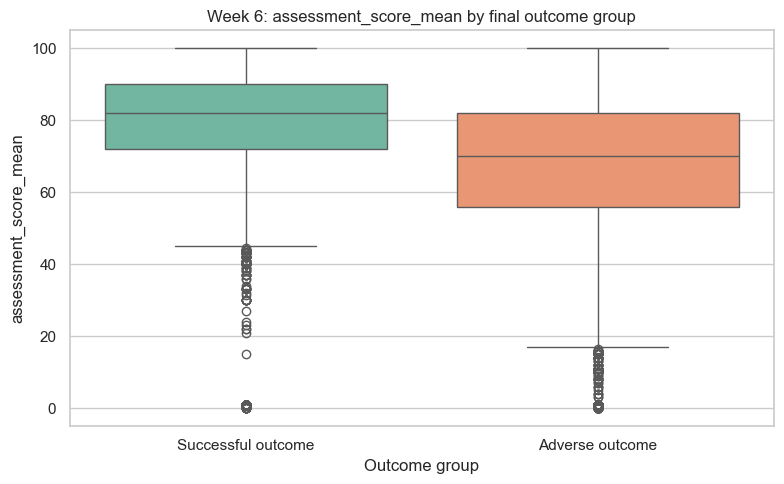

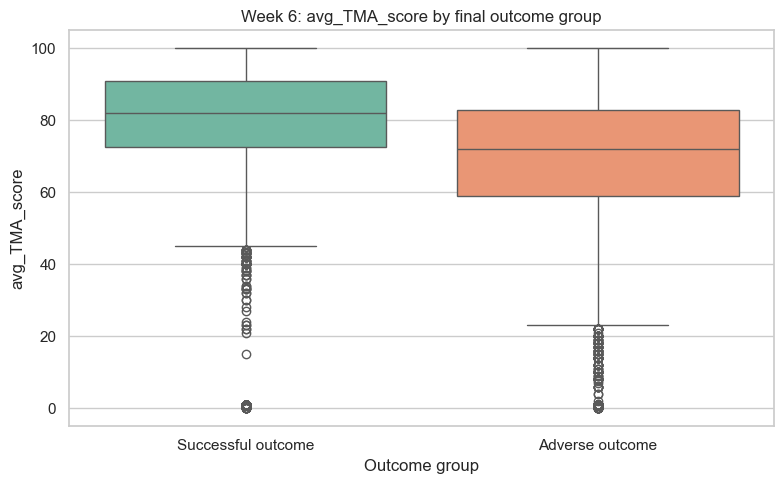

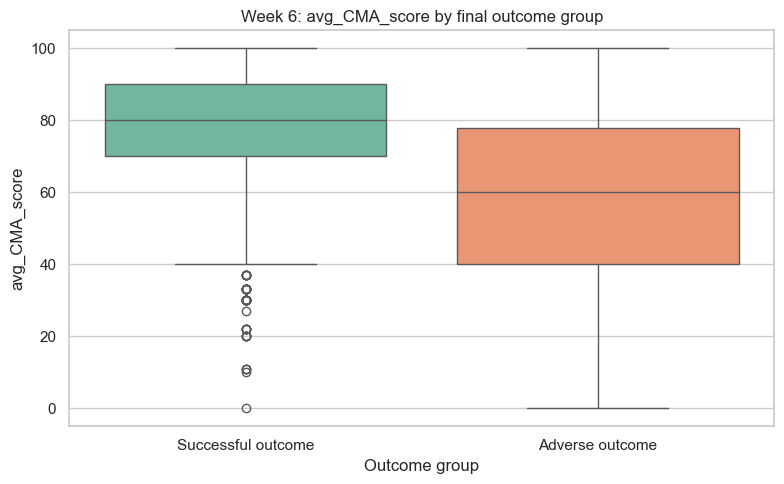

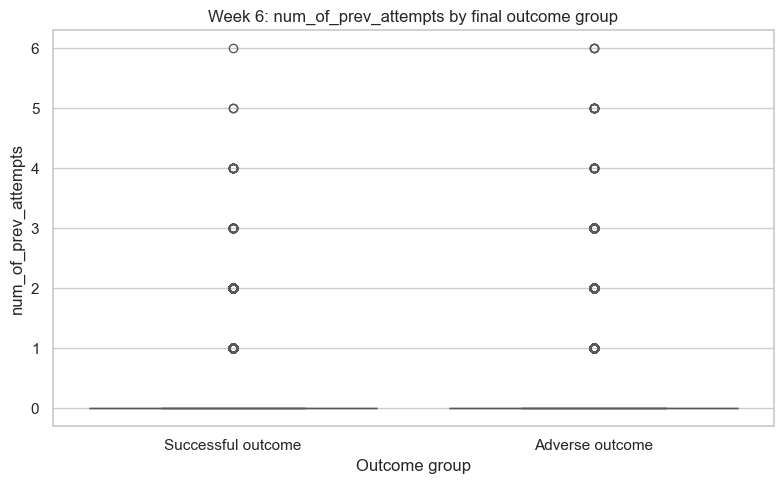

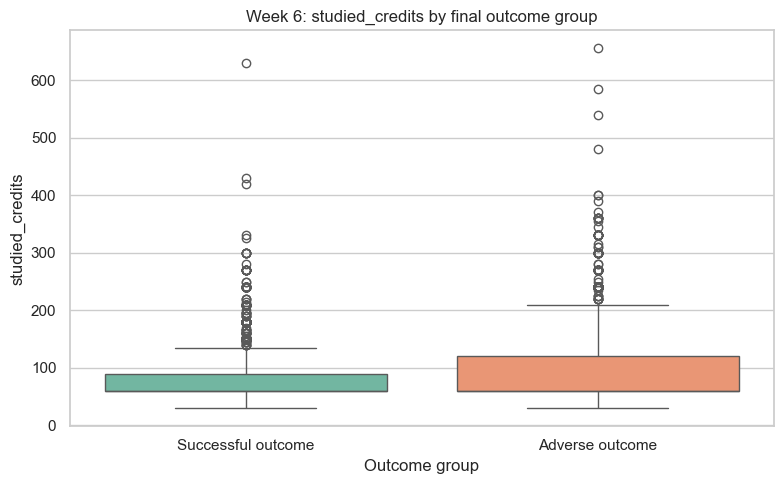

,window,feature,outcome_group,count,mean,median,standard_deviation
0,Week 2,total_clicks,Adverse outcome,17208.0,10.997327,0.0,71.949761
1,Week 2,total_clicks,Successful outcome,15385.0,32.261358,0.0,133.656233
2,Week 2,active_days,Adverse outcome,17208.0,0.554568,0.0,2.331866
3,Week 2,active_days,Successful outcome,15385.0,1.407085,0.0,4.167603
4,Week 2,unique_learning_sites,Adverse outcome,17208.0,1.252208,0.0,4.802289
5,Week 2,unique_learning_sites,Successful outcome,15385.0,2.658044,0.0,7.303501
6,Week 2,interaction_records,Adverse outcome,17208.0,3.260170,0.0,15.271374
7,Week 2,interaction_records,Successful outcome,15385.0,8.573351,0.0,27.743590
8,Week 2,assessment_record_count,Adverse outcome,17208.0,0.027022,0.0,0.162153
9,Week 2,assessment_record_count,Successful outcome,15385.0,0.047059,0.0,0.211772


Bivariate analysis completed for Weeks 2, 4 and 6.


In [24]:
# List the numerical features to compare
candidate_features = [
    "total_clicks",
    "active_days",
    "unique_learning_sites",
    "interaction_records",
    "assessment_record_count",
    "scored_assessment_count",
    "submitted_assessment_count",
    "assessment_submission_rate",
    "assessment_score_mean",
    "avg_TMA_score",
    "avg_CMA_score",
    "num_of_prev_attempts",
    "studied_credits"
]

# Create an empty list for the results
all_bivariate_rows = []

# Analyse each prediction window
for window, data in analytical_datasets.items():

    # Create readable outcome labels
    data = data.copy()

    data["outcome_group"] = data["target"].map({
        0: "Adverse outcome",
        1: "Successful outcome"
    })

    # Select numerical features available in this window
    numeric_features_window = [
        column
        for column in candidate_features
        if column in data.columns
        and pd.api.types.is_numeric_dtype(data[column])
    ]

    # Identify count features that need log transformation in graphs
    log_features_window = [
        column
        for column in [
            "total_clicks",
            "active_days",
            "unique_learning_sites",
            "interaction_records"
        ]
        if column in numeric_features_window
    ]

    # Analyse each numerical feature
    for column in numeric_features_window:

        # Calculate summary statistics by outcome group
        grouped_summary = (
            data.groupby("outcome_group")[column]
            .agg(["count", "mean", "median", "std"])
        )

        # Store the results for each outcome group
        for outcome_group, row in grouped_summary.iterrows():

            all_bivariate_rows.append({
                "window": f"Week {window}",
                "feature": column,
                "outcome_group": outcome_group,
                "count": row["count"],
                "mean": row["mean"],
                "median": row["median"],
                "standard_deviation": row["std"]
            })

        # Copy the feature and outcome columns for plotting
        plot_data = data[[column, "outcome_group"]].copy()

        # Use the original feature values by default
        plot_column = column
        y_label = column

        # Apply log transformation to count features for plotting
        if column in log_features_window:

            # Create transformed values for the graph only
            plot_data["plot_value"] = np.log1p(plot_data[column])

            # Use the transformed values in the graph
            plot_column = "plot_value"

            # Update the vertical-axis label
            y_label = f"log(1 + {column})"

        # Create the box plot
        plt.figure(figsize=(8, 5))

        # Compare the feature between the two outcome groups
        sns.boxplot(
            data=plot_data,
            x="outcome_group",
            y=plot_column,
            hue="outcome_group",
            palette="Set2",
            legend=False
        )

        # Add the graph title
        plt.title(
            f"Week {window}: {column} by final outcome group"
        )

        # Add the horizontal-axis label
        plt.xlabel("Outcome group")

        # Add the vertical-axis label
        plt.ylabel(y_label)

        # Arrange the graph neatly
        plt.tight_layout()

        # Save the graph
        plt.savefig(
            eda_folder / f"week_{window}_boxplot_{column}_by_outcome.png",
            dpi=300,
            bbox_inches="tight"
        )

        # Display the graph
        plt.show()

# Convert the results into a DataFrame
bivariate_df = pd.DataFrame(all_bivariate_rows)

# Display the summary results
display(bivariate_df)

# Save the bivariate summary
bivariate_df.to_csv(
    eda_folder / "numeric_features_by_outcome_all_windows.csv",
    index=False
)

print("Bivariate analysis completed for Weeks 2, 4 and 6.")



### Meaning of the bivariate results

The bivariate analysis compares each numerical feature between successful and adverse outcome groups at Weeks 2, 4 and 6. This helps identify which variables may contain useful information for classifying final outcomes before formal model training (Ozdemir, 2016).

The engagement variables show a consistent difference between the groups. At Week 2, successful-outcome students had higher mean total clicks than adverse-outcome students, 32.26 compared with 11.00. The same pattern continued at Week 4, 49.28 compared with 17.24, and at Week 6, 63.64 compared with 21.37. Successful-outcome students also had higher mean active days, learning sites and interaction records in every prediction window.

The medians for the engagement variables are zero in both groups. This means that many records contain no recorded activity, while a smaller group of students has much higher activity. The engagement distributions are therefore strongly skewed, and the overlap between the groups shows that engagement alone cannot perfectly classify the final outcome.

Assessment participation shows a similar pattern. Successful-outcome students had higher assessment-record counts, scored-assessment counts, submitted-assessment counts and submission rates than adverse-outcome students. The difference became clearer in Weeks 4 and 6. For example, the Week 6 mean submission rate was 0.89 for successful-outcome students and 0.54 for adverse-outcome students.

The assessment-score variables show the clearest separation between the outcome groups. In Week 6, the mean assessment score was 78.78 for successful-outcome students and 66.67 for adverse-outcome students. The mean TMA score was 79.10 compared with 68.38, while the mean CMA score was 79.44 compared with 57.12. The CMA result must be interpreted cautiously because only 4,273 CMA scores were available.

The previous-attempts variable was slightly higher for adverse-outcome students, with a Week 6 mean of 0.21 compared with 0.11 for successful-outcome students. Studied credits had the same median of 60 in both groups, but the adverse-outcome group had a higher mean because of several high values and outliers. These variables require cautious interpretation.

Overall, the results suggest that engagement, assessment participation and assessment scores may help distinguish successful and adverse outcomes. The results provide preliminary support for examining assessment and activity features in the modelling stage, but they do not prove causation or confirm that any feature will be important in the final models.

These findings support RQ1 by showing that early engagement and assessment variables contain observable differences between outcome groups. They also support RQ2 by showing that more information becomes available in the later windows, although the earliest practically useful window can only be identified after comparing model performance. The results support RQ3 by identifying assessment scores, submission measures and engagement features as candidate important predictors.

The hypotheses have not yet been accepted or rejected. H1 and H2 require model-performance comparisons, while H3 requires formal feature-importance results from the trained models. This analysis contributes to the research gap by examining the same types of predictors across the same student population at Weeks 2, 4 and 6.


## 8. Categorical outcome rates

This section counts how many students belong to each category and calculates the percentage with a successful outcome. This is appropriate for categorical data because categories such as gender, region or disability status should be examined through their counts and proportions, rather than treated as numerical measurements. (Ozdemir, 2016) <source id="bc3956e" passageId="bc3956e" title="Principles of Data Science" sourceType="library" sourceId="0UFjTbPQPHa9a_OBqo21U" authors="Sinan Ozdemir" sdType="attachment" sdPage="194" sdMimeType="application/pdf" />
The analysis helps answer RQ3 by showing whether outcome rates differ between groups. It may also indicate which categorical variables should be considered in the later predictive models..


,window,variable,category,count,successful_outcome_percent
0,Week 2,gender,F,14718,48.44
1,Week 2,gender,M,17875,46.19
2,Week 2,region,East Anglian Region,3340,48.98
3,Week 2,region,East Midlands Region,2365,45.71
4,Week 2,region,Ireland,1184,54.90
...,...,...,...,...,...
103,Week 6,age_band,0-35,22944,45.03
104,Week 6,age_band,35-55,9433,52.16
105,Week 6,age_band,55<=,216,61.57
106,Week 6,disability,N,29429,48.18


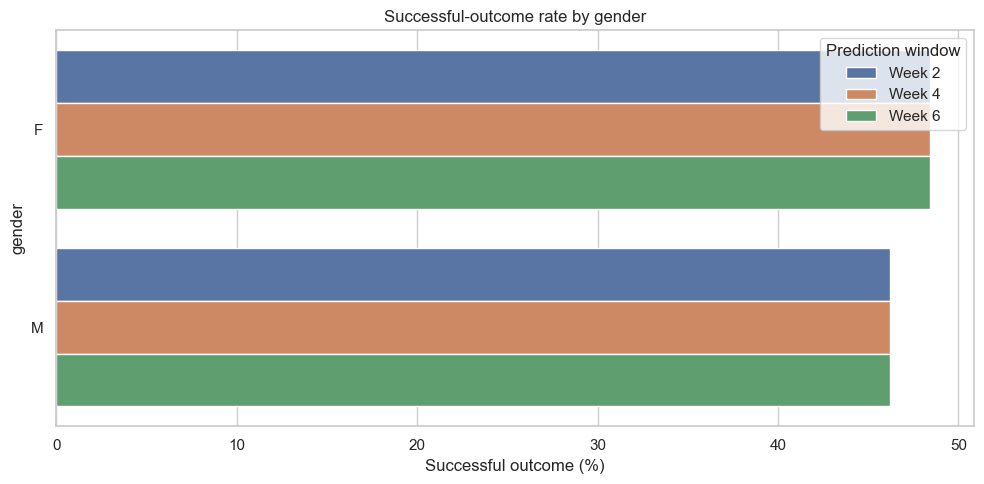

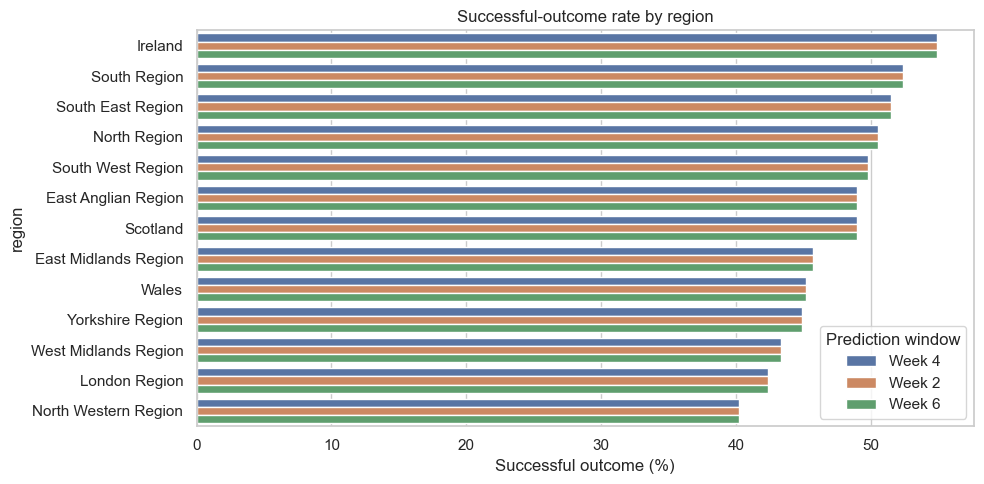

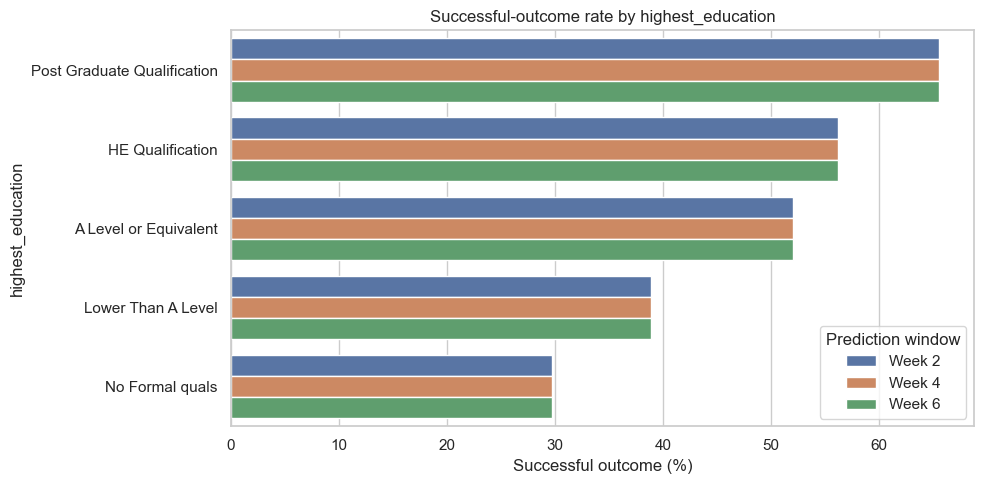

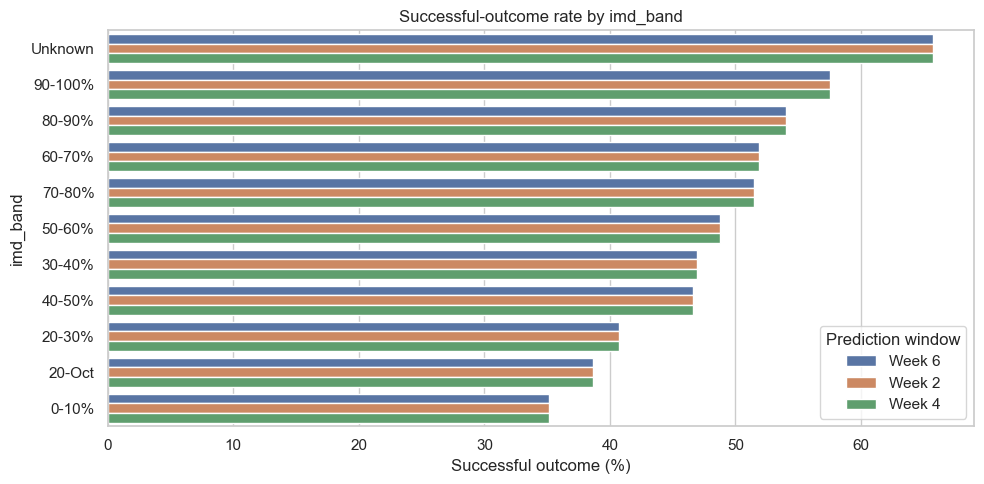

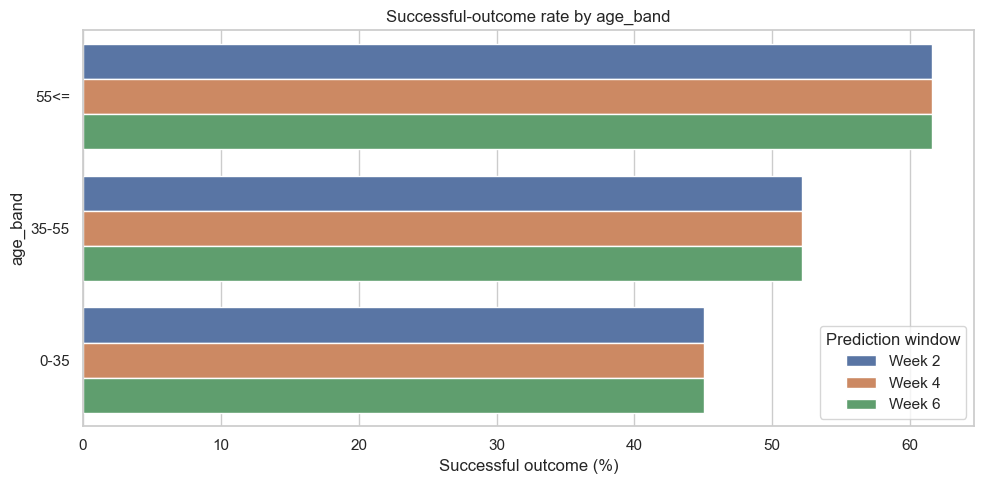

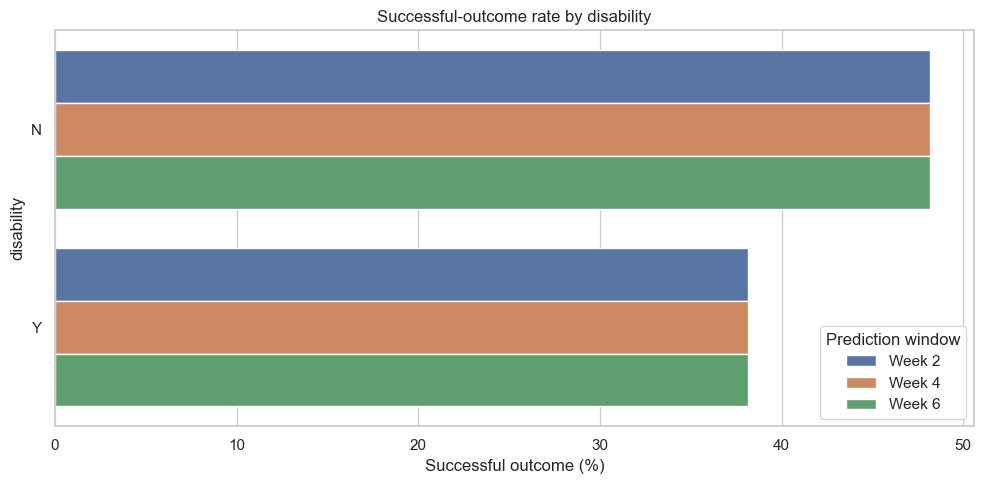

Categorical outcome-rate analysis completed for all available prediction windows.


In [25]:
# Summarise categorical outcome rates across all prediction windows

candidate_categorical_features = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

all_categorical_rows = []

# Analyse each prediction window stored in analytical_datasets
for window, data in analytical_datasets.items():

    data = data.copy()

    # Create a readable name for the prediction window
    window_label = str(window)

    if window_label.lower().startswith("week"):
        window_label = window_label.replace("_", " ").title()
    else:
        window_label = f"Week {window_label}"

    # Select categorical variables available in this window
    categorical_features_window = [
        column for column in candidate_categorical_features
        if column in data.columns
    ]

    # Analyse each categorical variable
    for column in categorical_features_window:

        # Treat missing category values as a separate category
        data["category_value"] = (
            data[column]
            .astype("object")
            .fillna("Missing")
        )

        # Calculate category count and successful-outcome rate
        grouped_summary = (
            data.groupby("category_value")["target"]
            .agg(
                count="size",
                successful_outcome_rate="mean"
            )
            .reset_index()
        )

        # Store each category's results
        for _, row in grouped_summary.iterrows():

            all_categorical_rows.append({
                "window": window_label,
                "variable": column,
                "category": row["category_value"],
                "count": int(row["count"]),
                "successful_outcome_percent": round(
                    row["successful_outcome_rate"] * 100,
                    2
                )
            })

# Convert the results into a DataFrame
categorical_df = pd.DataFrame(all_categorical_rows)

# Display the results
display(categorical_df)

# Save the summary table
categorical_df.to_csv(
    eda_folder / "categorical_outcome_rates_all_windows.csv",
    index=False
)

# Plot outcome rates for each categorical variable
for column in candidate_categorical_features:

    rate_data = categorical_df[
        categorical_df["variable"] == column
    ].sort_values(
        "successful_outcome_percent",
        ascending=False
    )

    if rate_data.empty:
        continue

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=rate_data,
        x="successful_outcome_percent",
        y="category",
        hue="window"
    )

    plt.title(f"Successful-outcome rate by {column}")
    plt.xlabel("Successful outcome (%)")
    plt.ylabel(column)
    plt.legend(title="Prediction window")
    plt.tight_layout()

    plt.savefig(
        eda_folder / f"categorical_outcome_rate_{column}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Categorical outcome-rate analysis completed for all available prediction windows.")


### Results
The categorical outcome rate analysis identified differences in successful outcomes across gender, region, highest education, IMD band, age band and disability status. The clearest patterns were observed for highest education, socioeconomic status, age and disability status. Students with higher educational qualifications and higher IMD bands generally had higher successful-outcome rates, while students recorded as having a disability had lower rates than those recorded as not having a disability. Regional rates also varied considerably, whereas the difference between male and female students was relatively small. These patterns were broadly consistent across Weeks 2, 4 and 6. The results identify categorical variables that may contribute to prediction and support RQ3, which examines the predictors associated with final pass or fail outcomes. However, the results are descriptive and do not determine which prediction window is earliest and reliable. That question must be answered later by comparing model performance across Weeks 2, 4 and 6 using the same analytical procedure, as required by the study’s research gap

## 9. Comparing feature accumulation across windows

This section checks whether cumulative engagement and assessment information increases from week 2 to week 6 and whether the pattern differs between outcome groups.


,window,outcome_group,feature,mean,median
0,2,Adverse outcome,total_clicks,10.997327,0.0
1,2,Adverse outcome,active_days,0.554568,0.0
2,2,Adverse outcome,unique_learning_sites,1.252208,0.0
3,2,Adverse outcome,assessment_score_mean,67.280172,69.0
4,2,Adverse outcome,avg_TMA_score,67.280172,69.0
5,2,Adverse outcome,assessment_submission_rate,0.024988,0.0
6,2,Successful outcome,total_clicks,32.261358,0.0
7,2,Successful outcome,active_days,1.407085,0.0
8,2,Successful outcome,unique_learning_sites,2.658044,0.0
9,2,Successful outcome,assessment_score_mean,73.629834,75.0


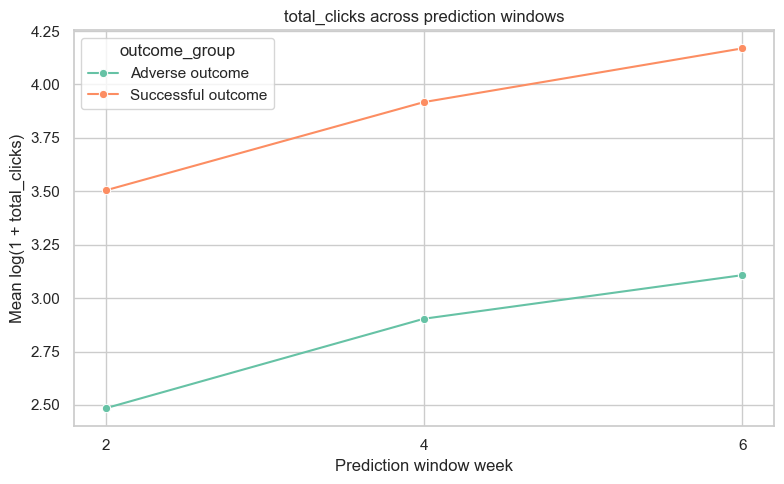

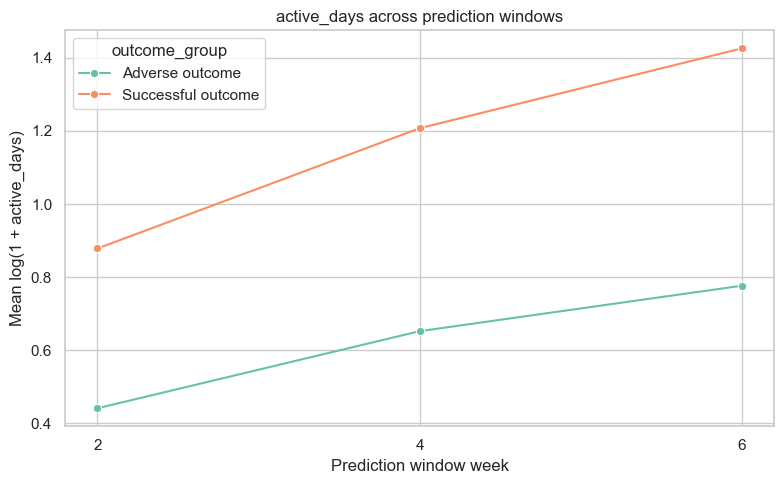

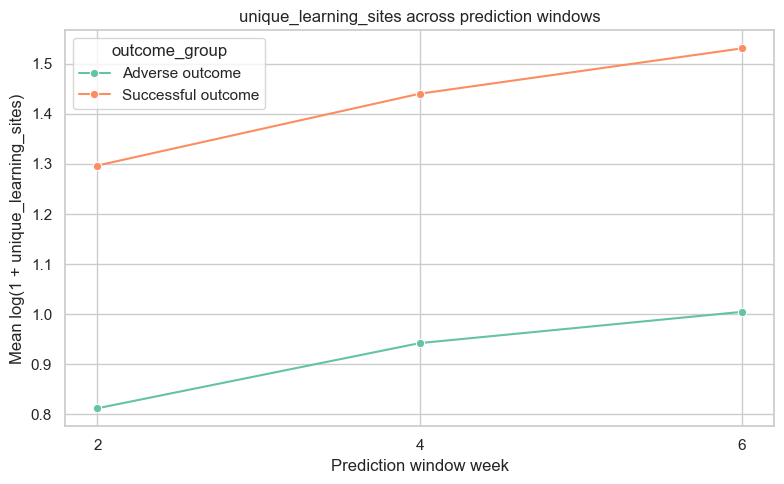

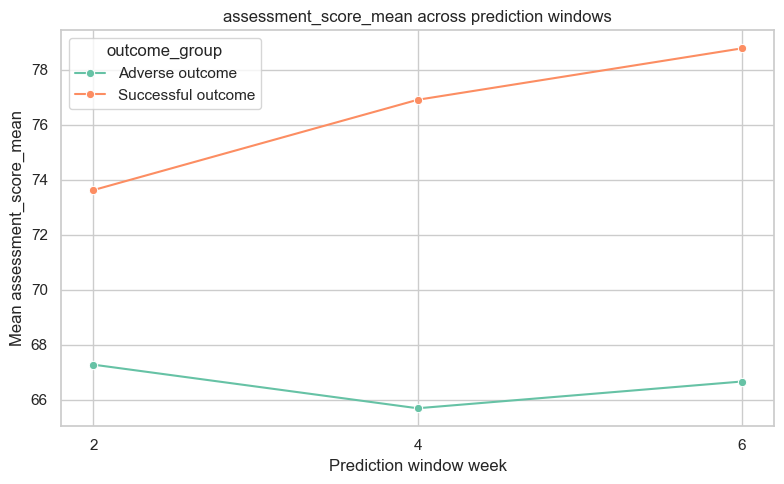

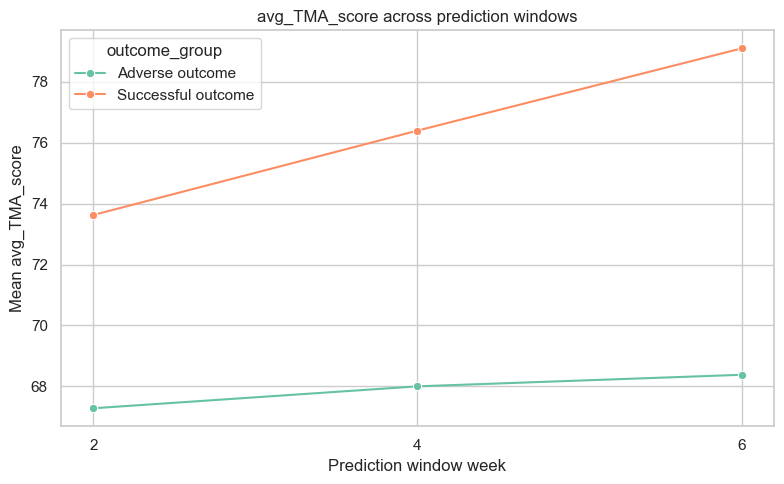

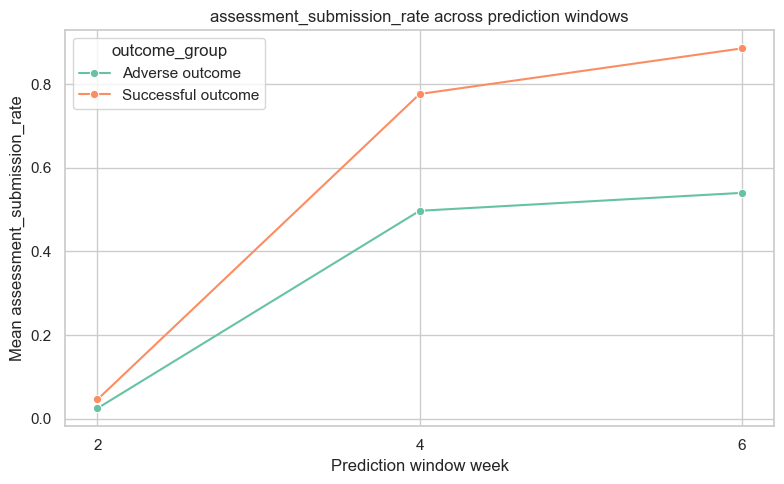

In [26]:
# Comparing important feature summaries across the three windows
window_features = [column for column in ["total_clicks", "active_days", "unique_learning_sites", "assessment_score_mean", "avg_TMA_score", "avg_CMA_score", "assessment_submission_rate"] if all(column in data.columns for data in analytical_datasets.values())]
window_rows = []
for window, data in analytical_datasets.items():
    for target_value, group in data.groupby("target"):
        for column in window_features:
            window_rows.append({"window": window, "outcome_group": "Successful outcome" if target_value == 1 else "Adverse outcome", "feature": column, "mean": group[column].mean(), "median": group[column].median()})

window_summary_df = pd.DataFrame(window_rows)
display(window_summary_df)
window_summary_df.to_csv(eda_folder / "feature_summary_by_window_and_outcome.csv", index=False)

for column in window_features:
    plot_data = window_summary_df[window_summary_df["feature"] == column].copy()
    y_column = "mean"
    y_label = f"Mean {column}"
    if column in log_features:
        plot_data[y_column] = np.log1p(plot_data[y_column])
        y_label = f"Mean log(1 + {column})"
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=plot_data, x="window", y=y_column, hue="outcome_group", marker="o", palette="Set2")
    plt.title(f"{column} across prediction windows")
    plt.xlabel("Prediction window week")
    plt.ylabel(y_label)
    plt.xticks([2, 4, 6])
    plt.tight_layout()
    plt.savefig(eda_folder / f"window_comparison_{column}.png", dpi=300, bbox_inches="tight")
    plt.show()


 Active days:
> Both lines increase from Week 2 to Week 6, showing that students become active on more days as the course continues. The successful-outcome group remains clearly above the adverse-outcome group at all three windows. This suggests that regular activity is linked with better final outcomes.
This feature shows a clear difference between the two groups from Week 2.


Unique learning sites
> The lines rise from Week 2 to Week 6, meaning that students use a wider range of learning sites over time. The successful-outcome group consistently uses more learning sites than the adverse-outcome group. This suggests that successful students interact with a broader range of online learning resources.
The difference is present at Week 2, so this feature may provide an early warning signal.


Assessment score mean
> The successful-outcome group has higher average assessment scores at every prediction window. Its average score increases from approximately 74 at Week 2 to approximately 79 at Week 6. The adverse-outcome group remains lower, at approximately 67 across the three windows.
The gap between the groups becomes larger after Week 2. This suggests that early assessment performance may help distinguish students who are likely to achieve a successful outcome from those at risk of an adverse outcome.

 Average TMA score
> The successful-outcome group shows a clear increase in average TMA score from Week 2 to Week 6. The adverse-outcome group changes very little. The successful-outcome group remains higher at every window, showing that TMA performance separates the two groups.
This indicates that TMA scores may be useful predictors because the difference is already visible at Week 2.


 Assessment submission rate
> Both groups have very low submission rates at Week 2, but the successful-outcome group has a slightly higher rate. From Week 2 to Week 4, both lines rise sharply. The successful-outcome group then reaches approximately 0.89, while the adverse-outcome group reaches approximately 0.54 by Week 6.

## 10. Multivariate analysis: correlations and pair plot

This section asks two simple questions.
1. Do numerical features move together?

For example, do students who have more clicks also have more active days?

2. Which features are most related to the final outcome?

For example, is assessment score more related to success than total clicks?

A positive correlation means that both values usually increase together. A negative correlation means that one value tends to increase while the other decreases. Correlation values range from -1 to +1. Values close to either end show a stronger relationship. (Ozdemir, 2016)


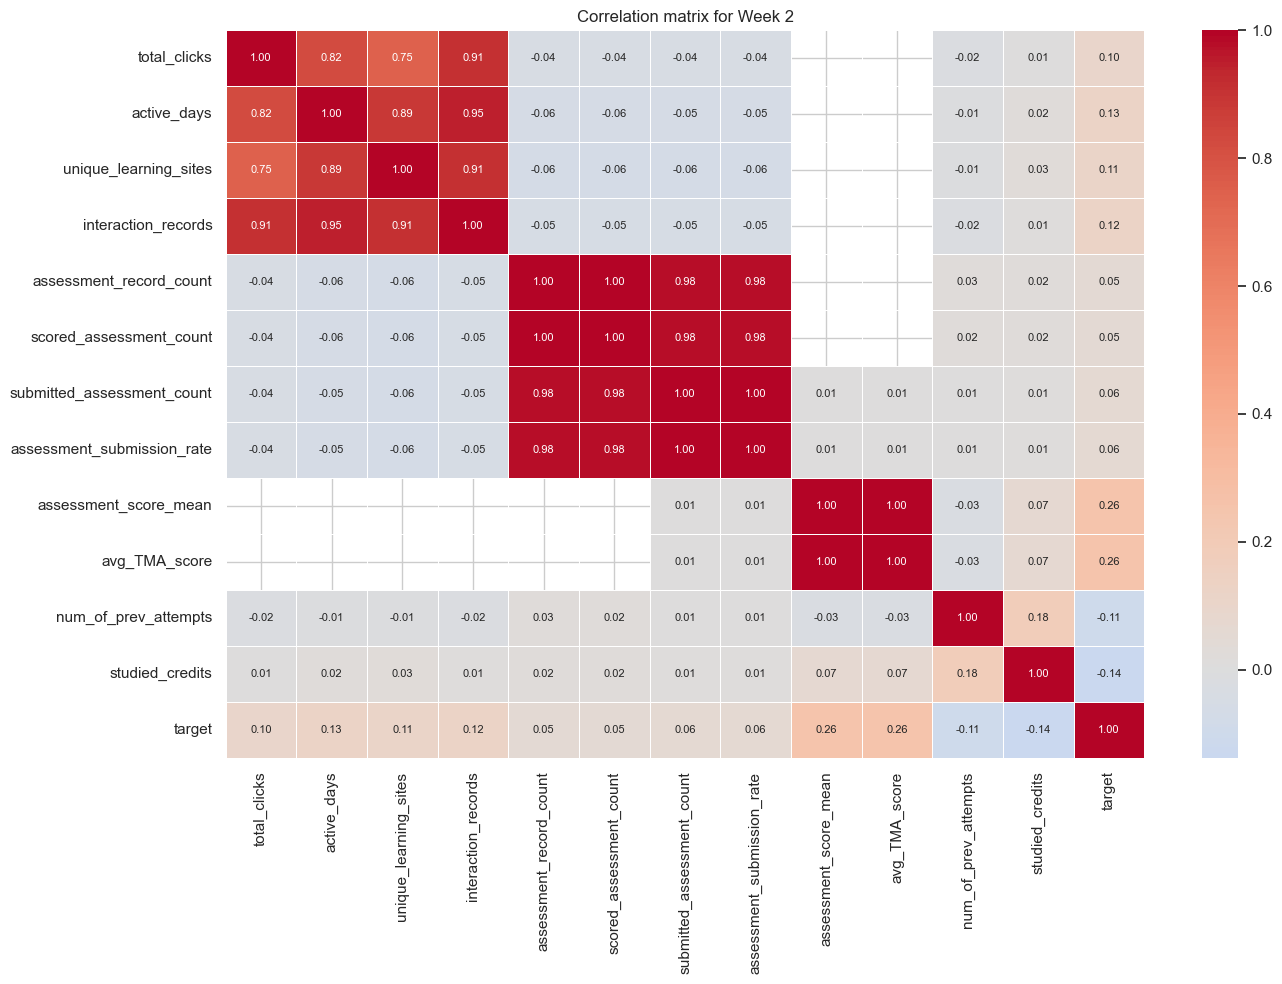

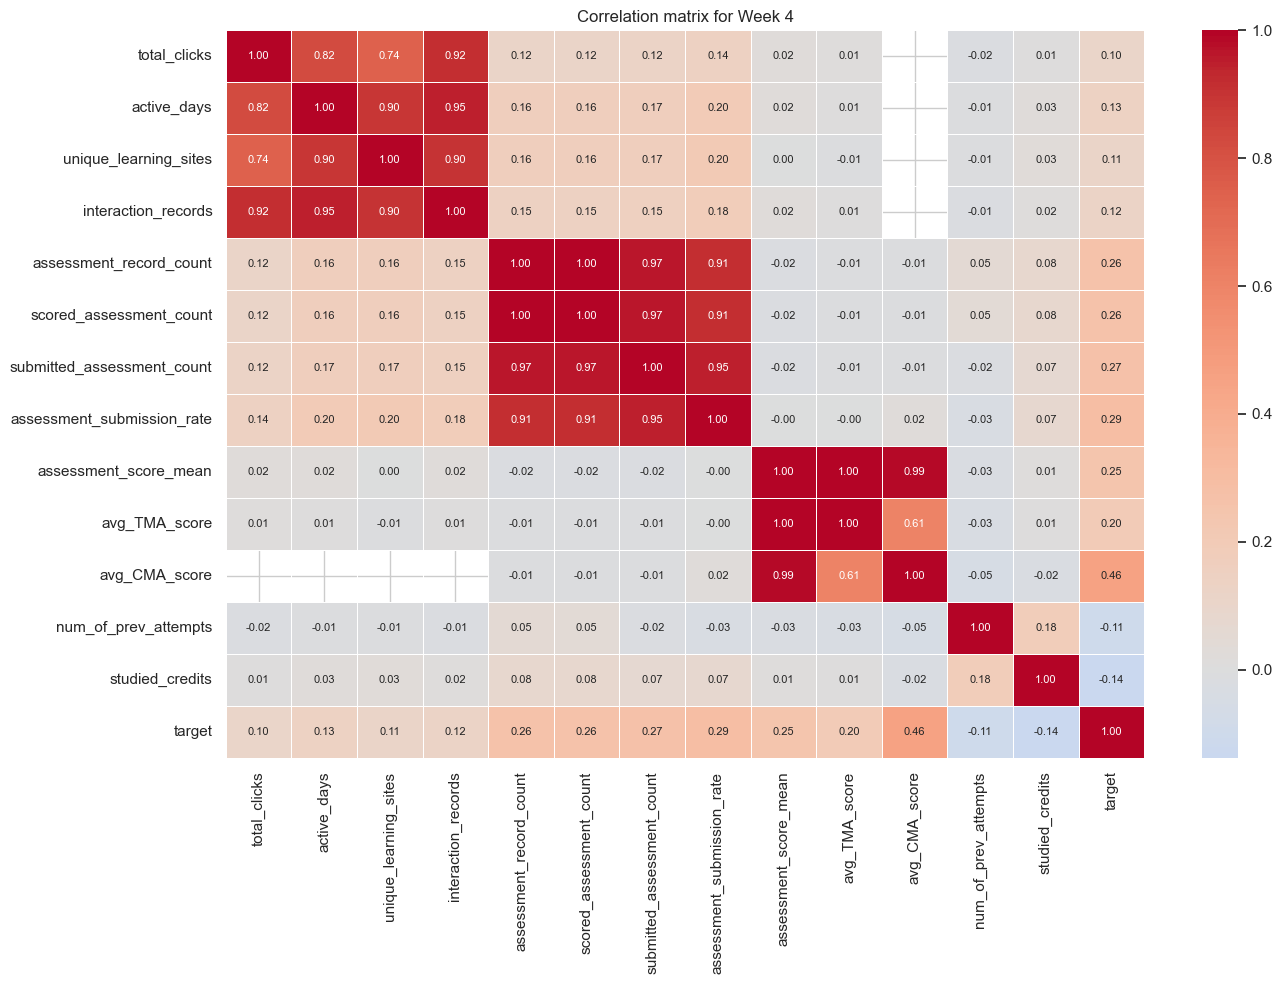

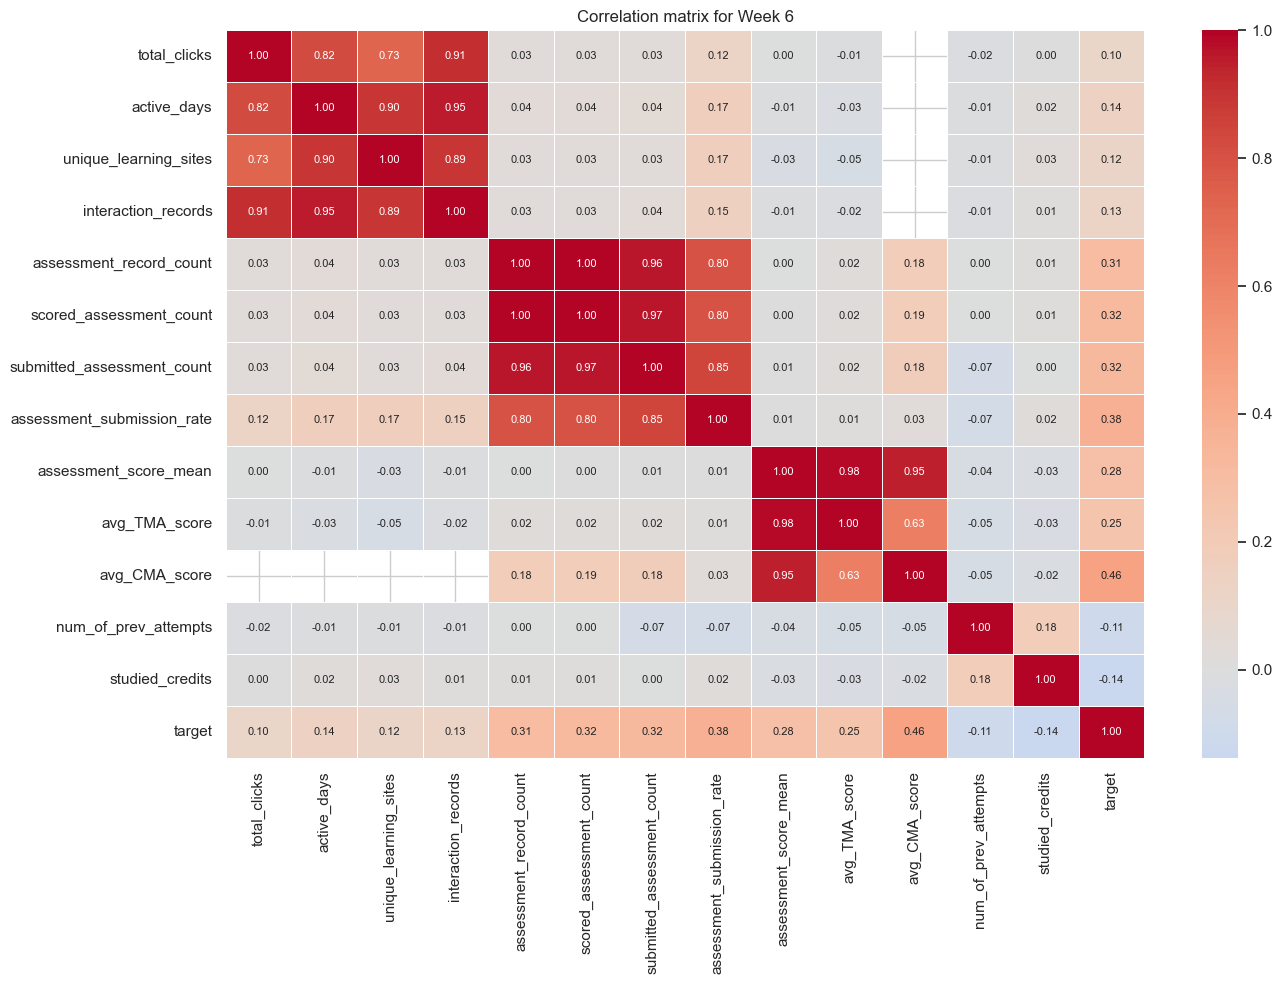

Correlation with target:


,window,feature,correlation_with_target
0,Week 2,assessment_score_mean,0.255302
1,Week 2,avg_TMA_score,0.255302
2,Week 2,studied_credits,-0.138630
3,Week 2,active_days,0.126887
4,Week 2,interaction_records,0.119404
5,Week 2,unique_learning_sites,0.114083
6,Week 2,num_of_prev_attempts,-0.105460
7,Week 2,total_clicks,0.099960
8,Week 2,submitted_assessment_count,0.057194
9,Week 2,assessment_submission_rate,0.057194


Highly correlated feature pairs:


,window,feature_1,feature_2,correlation
5,Week 2,assessment_record_count,scored_assessment_count,1.000
10,Week 2,submitted_assessment_count,assessment_submission_rate,1.000
11,Week 2,assessment_score_mean,avg_TMA_score,1.000
6,Week 2,assessment_record_count,submitted_assessment_count,0.978
7,Week 2,assessment_record_count,assessment_submission_rate,0.978
8,Week 2,scored_assessment_count,submitted_assessment_count,0.978
9,Week 2,scored_assessment_count,assessment_submission_rate,0.978
3,Week 2,active_days,interaction_records,0.949
1,Week 2,total_clicks,interaction_records,0.910
4,Week 2,unique_learning_sites,interaction_records,0.908


In [33]:
# Store target-correlation results from all prediction windows
all_target_correlations = []

# Store highly correlated feature pairs from all prediction windows
all_high_correlation_pairs = []


# Analyse each prediction window
for window, data in analytical_datasets.items():

    data = data.copy()

    # Create a readable window name
    window_label = str(window)

    if not window_label.lower().startswith("week"):
        window_label = f"Week {window_label}"

    # Select numerical features available in this window
    correlation_features = [
        column
        for column in numeric_features + ["target"]
        if column in data.columns
    ]

    # Calculate the correlation matrix
    correlation_matrix = data[
        correlation_features
    ].corr(numeric_only=True)

    # Display the correlation matrix as a heatmap
    plt.figure(figsize=(14, 10))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        annot=True,             # Display correlation numbers
        fmt=".2f",              # Display numbers to two decimal places
        linewidths=0.5,         # Add lines between cells
        annot_kws={"size": 8}
    )

    plt.title(f"Correlation matrix for {window_label}")
    plt.tight_layout()

    # Save the heatmap
    window_number = (
        window_label
        .lower()
        .replace("week", "")
        .replace(" ", "")
        .replace("_", "")
    )

    plt.savefig(
        eda_folder / f"correlation_matrix_week{window_number}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # Calculate each feature's correlation with the target
    target_correlations = (
        correlation_matrix["target"]
        .drop("target")
        .sort_values(
            key=lambda values: values.abs(),
            ascending=False
        )
        .rename("correlation_with_target")
        .reset_index()
    )

    # Rename the feature column
    target_correlations.columns = [
        "feature",
        "correlation_with_target"
    ]

    # Add the prediction window
    target_correlations.insert(
        0,
        "window",
        window_label
    )

    # Store the results
    all_target_correlations.append(
        target_correlations
    )


    # Identify highly correlated pairs of predictors
    feature_only = correlation_matrix.drop(
        index="target",
        columns="target",
        errors="ignore"
    )

    for first_index, first_feature in enumerate(
        feature_only.columns
    ):

        for second_feature in feature_only.columns[
            first_index + 1:
        ]:

            correlation_value = feature_only.loc[
                first_feature,
                second_feature
            ]

            # Store pairs with an absolute correlation of 0.80 or higher
            if (
                pd.notna(correlation_value)
                and abs(correlation_value) >= 0.80
            ):

                all_high_correlation_pairs.append({
                    "window": window_label,
                    "feature_1": first_feature,
                    "feature_2": second_feature,
                    "correlation": round(
                        correlation_value,
                        3
                    )
                })


# Combine target-correlation results from all windows
target_correlations_df = pd.concat(
    all_target_correlations,
    ignore_index=True
)

# Combine highly correlated feature pairs
high_correlation_pairs_df = pd.DataFrame(
    all_high_correlation_pairs
)

# Sort target correlations by the strength of the relationship
target_correlations_df = (
    target_correlations_df
    .assign(
        absolute_correlation=lambda dataframe:
        dataframe["correlation_with_target"].abs()
    )
    .sort_values(
        ["window", "absolute_correlation"],
        ascending=[True, False]
    )
    .drop(columns="absolute_correlation")
)

# Sort highly correlated pairs
if not high_correlation_pairs_df.empty:

    high_correlation_pairs_df = (
        high_correlation_pairs_df
        .assign(
            absolute_correlation=lambda dataframe:
            dataframe["correlation"].abs()
        )
        .sort_values(
            ["window", "absolute_correlation"],
            ascending=[True, False]
        )
        .drop(columns="absolute_correlation")
    )


# Display the results
print("Correlation with target:")
display(target_correlations_df)

print("Highly correlated feature pairs:")
display(high_correlation_pairs_df)


# Save the correlation results
target_correlations_df.to_csv(
    eda_folder / "target_correlations_all_windows.csv",
    index=False
)

high_correlation_pairs_df.to_csv(
    eda_folder / "high_correlation_pairs_all_windows.csv",
    index=False
)


# Create pair plots using selected numerical features
pairplot_features = [
    "total_clicks",
    "active_days",
    "unique_learning_sites",
    "assessment_score_mean",
    "assessment_submission_rate"
]




The correlation analysis showed that assessment-related variables had stronger relationships with the final outcome than basic engagement variables. At Week 2, assessment score mean and average TMA score had the strongest positive correlations with the target, although their relationships were moderate. By Week 4 and Week 6, CMA score, assessment submission rate and assessment counts showed stronger positive relationships with successful outcomes. This indicates that students who submit more assessments and achieve higher assessment scores are more likely to obtain a successful final outcome. In contrast, total clicks, active days and unique learning sites had positive but weak correlations with the target. Several predictor pairs were also highly correlated, including assessment counts, assessment scores and engagement counts. This suggests that some features contain similar information and should be checked for redundancy during modelling. Overall, the findings support RQ3 by identifying assessment performance and assessment completion as important candidate predictors. They also provide early evidence for RQ2, although model performance metrics are still required to determine the earliest reliable prediction window.

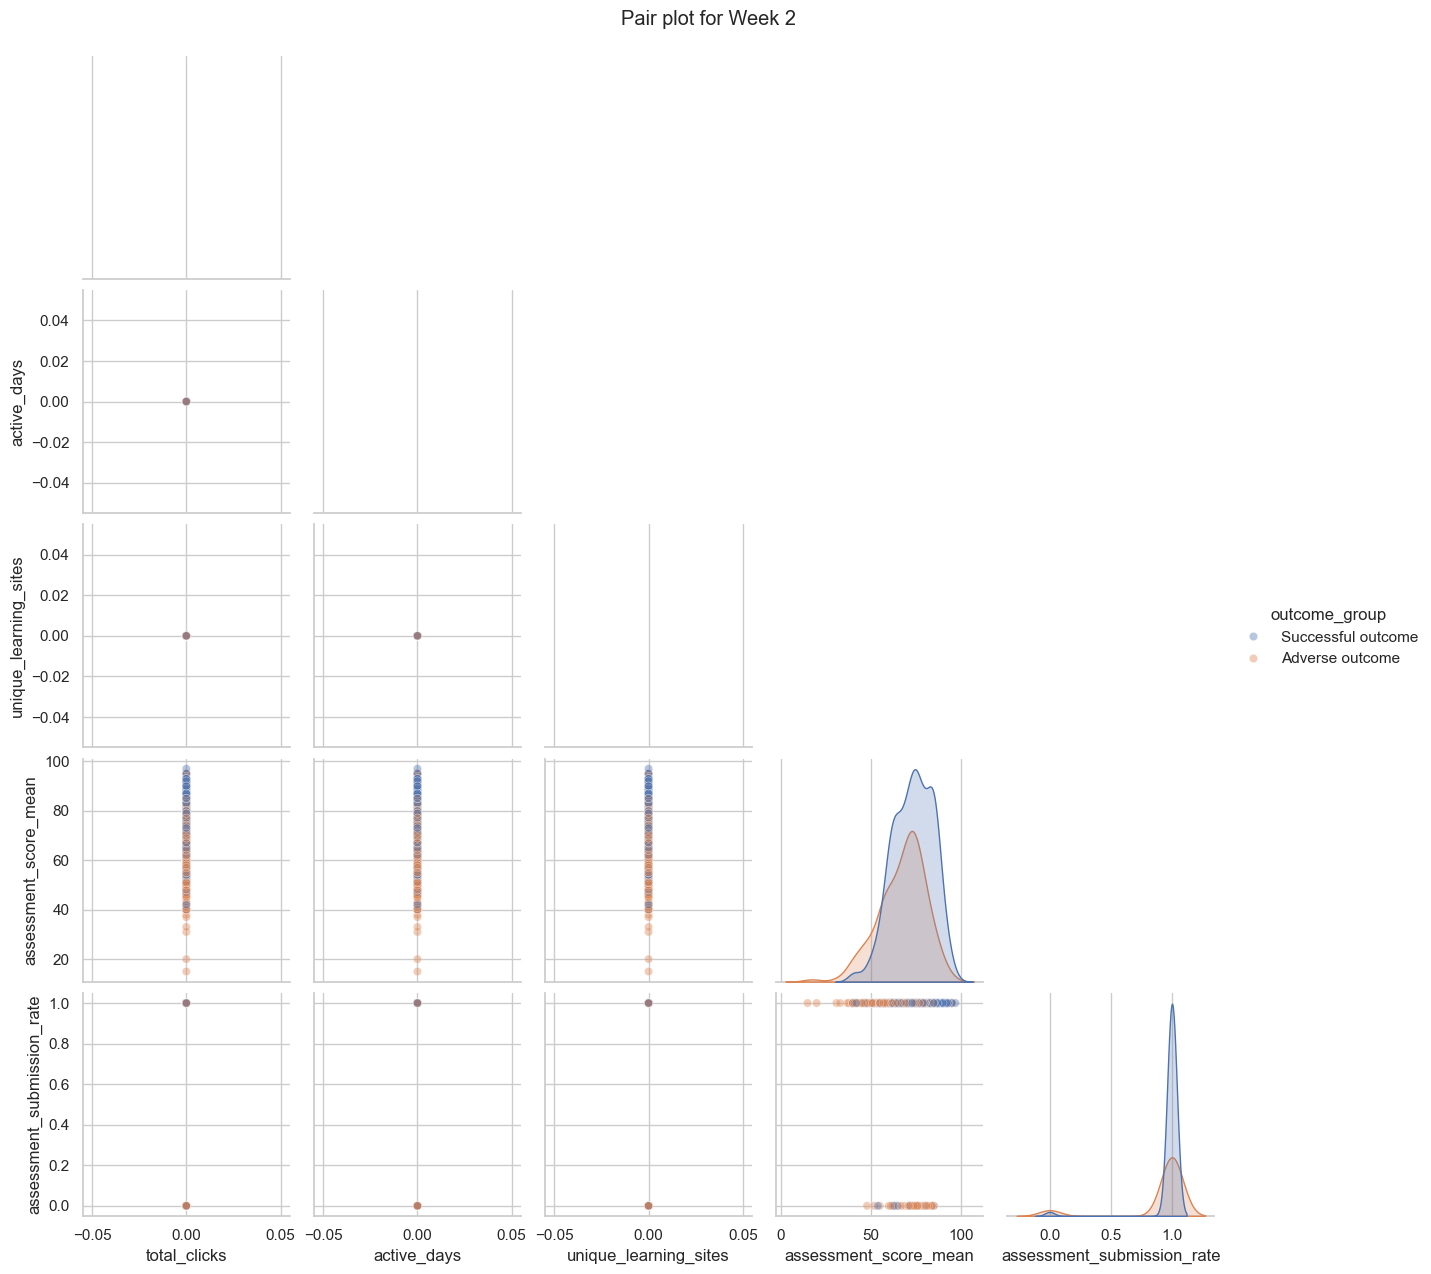

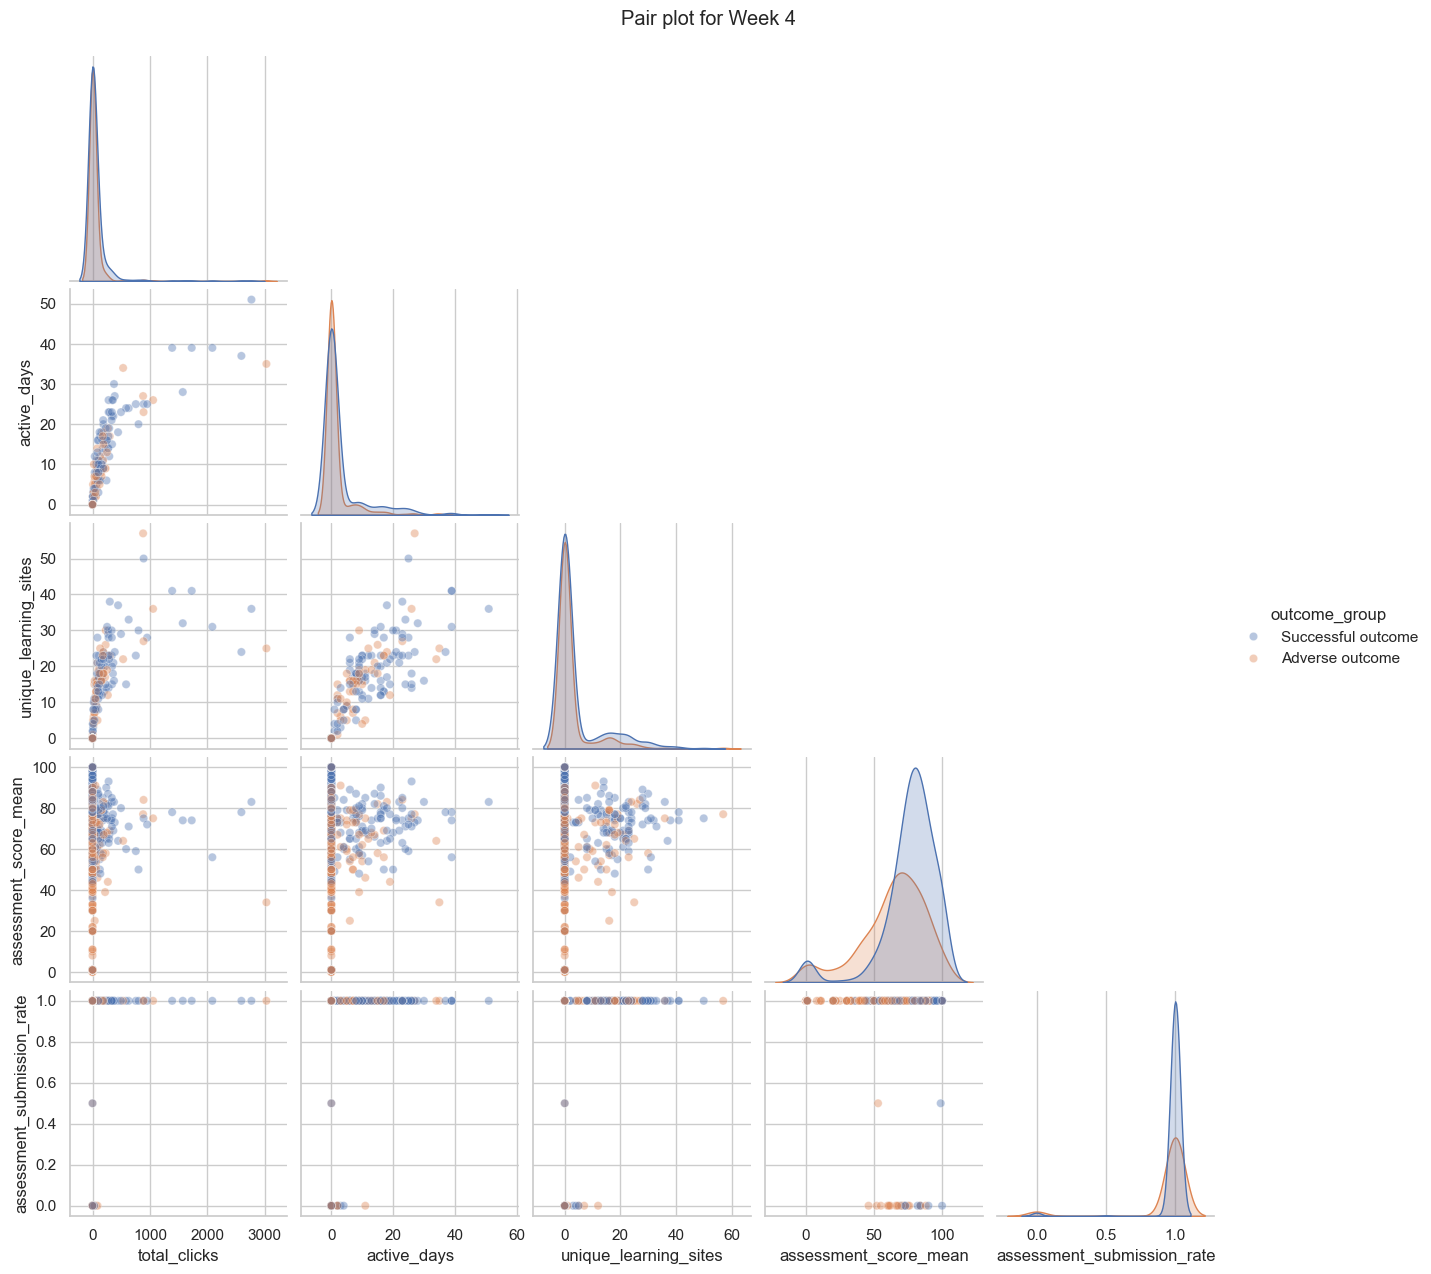

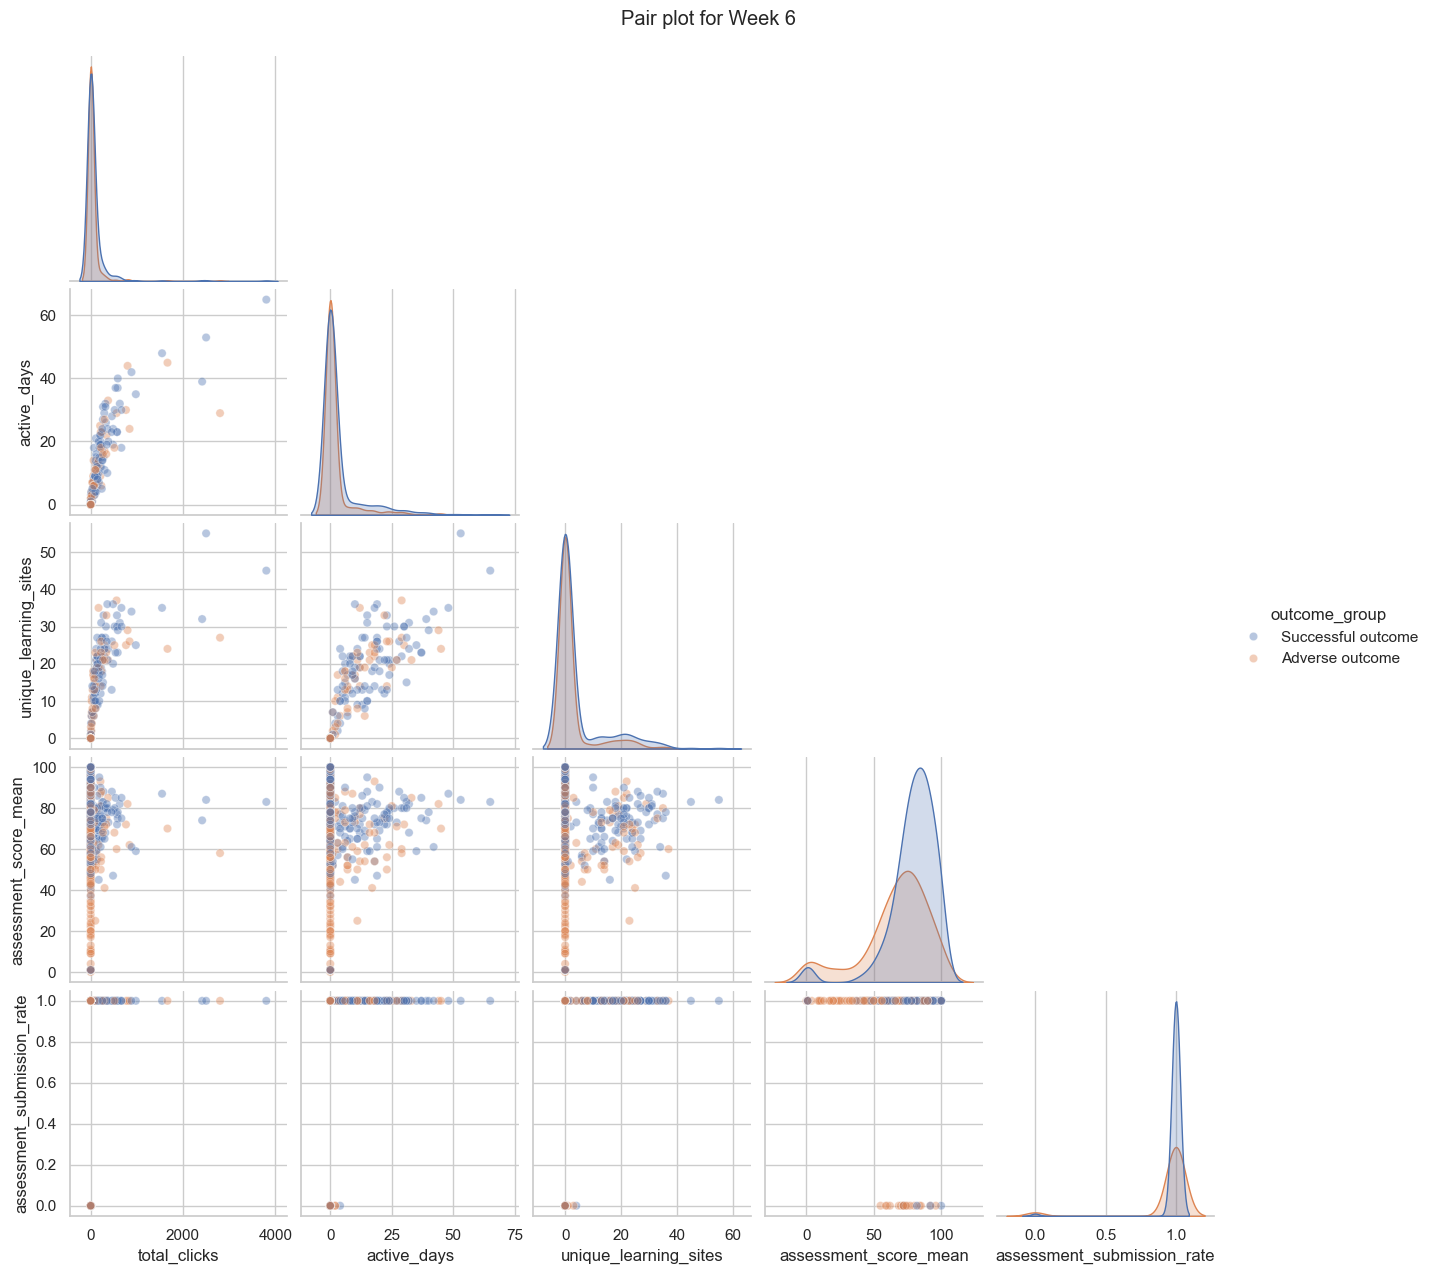

Multivariate analysis completed for Weeks 2, 4 and 6.


In [34]:
# Create one pair plot for each prediction window
for window, data in analytical_datasets.items():

    data = data.copy()

    window_label = str(window)

    if not window_label.lower().startswith("week"):
        window_label = f"Week {window_label}"

    window_number = (
        window_label
        .lower()
        .replace("week", "")
        .replace(" ", "")
        .replace("_", "")
    )

    # Select features that are available in this window
    available_pairplot_features = [
        column
        for column in pairplot_features
        if column in data.columns
    ]

    if len(available_pairplot_features) < 2:
        continue

    # Keep the selected features and remove missing values
    pair_data = data[
        available_pairplot_features + ["target"]
    ].dropna()

    if pair_data.empty:
        continue

    # Use a sample to keep the pair plot clear and quick
    sample_size = min(800, len(pair_data))

    pair_data = pair_data.sample(
        n=sample_size,
        random_state=42
    )

    # Create readable outcome labels
    pair_data["outcome_group"] = pair_data["target"].map({
        0: "Adverse outcome",
        1: "Successful outcome"
    })

    # Create the pair plot
    pair_plot = sns.pairplot(
        pair_data.drop(columns=["target"]),
        vars=available_pairplot_features,
        hue="outcome_group",
        corner=True,
        plot_kws={"alpha": 0.4}
    )

    pair_plot.fig.suptitle(
        f"Pair plot for {window_label}",
        y=1.02
    )

    pair_plot.fig.savefig(
        eda_folder / f"pairplot_week{window_number}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(pair_plot.fig)


print(
    "Multivariate analysis completed for Weeks 2, 4 and 6."
)


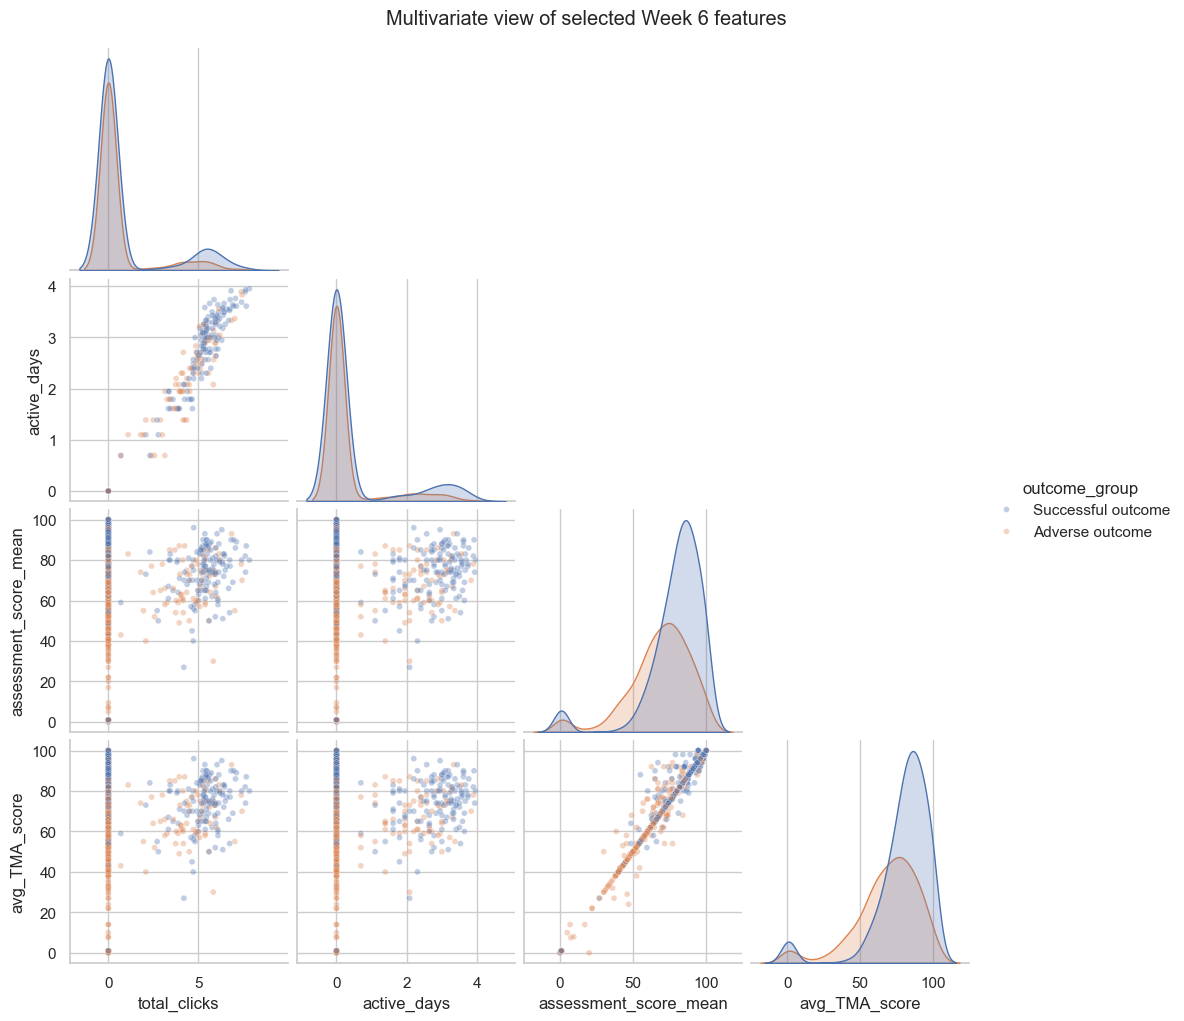

In [35]:
# Pair plot using a reproducible sample
pair_features = [column for column in ["total_clicks", "active_days", "assessment_score_mean", "avg_TMA_score"] if column in week6.columns]
if len(pair_features) >= 2:
    pair_data = week6[pair_features + ["outcome_group"]].sample(n=min(2000, len(week6)), random_state=42).dropna()
    for column in ["total_clicks", "active_days"]:
        if column in pair_data.columns:
            pair_data[column] = np.log1p(pair_data[column])
    pair_grid = sns.pairplot(pair_data, hue="outcome_group", corner=True, plot_kws={"alpha": 0.35, "s": 18})
    pair_grid.fig.suptitle("Multivariate view of selected Week 6 features", y=1.02)
    pair_grid.savefig(eda_folder / "pairplot_week6.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("At least two features are needed for the pair plot.")


The pair plots were used to compare the distribution and relationships of selected numerical features across the successful and adverse outcome groups. Across all three prediction windows, successful-outcome students generally had higher engagement and assessment values. The clearest differences were observed for assessment score and assessment submission rate, while total clicks, active days and unique learning sites showed weaker separation and greater overlap. Several engagement variables also increased together, indicating that students who were active on more days generally produced more clicks and accessed more learning sites. Although differences between the outcome groups were visible from Week 2 and became clearer for some assessment variables by Weeks 4 and 6, the overlap between groups shows that no single feature can classify outcomes perfectly. These results support RQ3 by identifying assessment performance and submission behaviour as important candidate predictors. They also contribute to RQ2, but model performance results are still required to identify the earliest reliable prediction window.

## 11. Outlier review and modelling handover

Potential outliers are counted using the interquartile-range rule. They are not deleted automatically because unusually high activity may be genuine behaviour. The final modelling pipeline should decide whether transformation or robust handling is justified.


In [36]:
# Reviewing potential IQR outliers without deleting them
# Create a clear list of categorical features for the handover summary

categorical_features_for_handover = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

# Create a summary of the completed EDA

handover = pd.DataFrame([{
    "week_2_rows": len(analytical_datasets[2]),
    "week_4_rows": len(analytical_datasets[4]),
    "week_6_rows": len(analytical_datasets[6]),

    "week_6_successful_percent": round(
        analytical_datasets[6]["target"].mean() * 100,
        2
    ),

    "week_6_adverse_percent": round(
        (1 - analytical_datasets[6]["target"].mean()) * 100,
        2
    ),

    "numeric_features_reviewed": ", ".join(
        numeric_features
    ),

    "categorical_features_reviewed": ", ".join(
        categorical_features_for_handover
    ),

    "high_correlation_pair_count": len(
        high_correlation_pairs_df
    )
}])

# Display the handover summary
display(handover)

# Save the handover summary
handover.to_csv(
    eda_folder / "eda_handover_summary.csv",
    index=False
)

print(
    "EDA tables and figures were saved in:",
    eda_folder
)


,week_2_rows,week_4_rows,week_6_rows,week_6_successful_percent,week_6_adverse_percent,numeric_features_reviewed,categorical_features_reviewed,high_correlation_pair_count
0,32593,32593,32593,47.2,52.8,"total_clicks, active_days, unique_learning_sit...","gender, region, highest_education, imd_band, a...",37


EDA tables and figures were saved in: c:\Users\pc\OneDrive - ADvTECH Ltd\SEM 2\Research in Programming and Data Analytics\OUALD\oulad_outputs\eda


The EDA handover summary confirmed that each prediction window contained 32,593 student records. This consistent sample size supports a fair comparison between Weeks 2, 4 and 6. The outcome distribution consisted of 47.2% successful outcomes and 52.8% adverse outcomes, providing a majority-class baseline of 52.8% for the modelling stage. The planned numerical and categorical features were reviewed, including engagement, assessment and student-background variables. The analysis also identified 37 high-correlation feature pairs across the prediction windows, indicating that some predictors contain similar information. These relationships will be considered during modelling to reduce redundancy and improve interpretation. The EDA therefore provides a clear foundation for testing whether early engagement and assessment data can predict final outcomes and for identifying the earliest reliable prediction window.

## References

James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J. 2023. *An introduction to statistical learning: With applications in Python*. 1st ed. Cham: Springer. [Online]. Available at: https://doi.org/10.1007/978-3-031-38747-0 [Accessed 26 August 2026].


Kuzilek, J., Hlosta, M. and Zdráhal, Z. 2017. ‘Open University Learning Analytics dataset’. *Scientific Data*, 4(1), article 170171. [Online]. Available at: [https://doi.org/10.1038/sdata.2017.171](https://doi.org/10.1038/sdata.2017.171) [Accessed 26 August 2026]. <source id="XPIdp9M0JC0r3W6tLp8tf" title="10.1038/sdata.2017.171" sourceType="external" url="https://doi.org/10.1038/sdata.2017.171" />


Open University  n.d. Open University Learning Analytics dataset. [Online]. Available at: [https://analyse.kmi.open.ac.uk/open_dataset](https://analyse.kmi.open.ac.uk/open_dataset) [Accessed 26 August 2026].


Ozdemir, S. 2016. *Principles of data science. 1st ed.* Packt Publishing. [Online]. Available at: [https://www.packtpub.com/en-us/product/principles-of-data-science-9781785887918](https://www.packtpub.com/en-us/product/principles-of-data-science-9781785887918) [Accessed 26 August 2026].
